# CC3092 · Laboratorio #8 — Series de tiempo y forecasting

## 0. Instalación, reproducibilidad y presupuesto computacional

In [2]:
%pip -q install "holidays>=0.60" "statsforecast>=2.0" "neuralforecast>=3.0" "lightgbm>=4.0" "chronos-forecasting>=2.0" "pyarrow>=15" "seaborn>=0.13"

In [3]:
import os, gc, io, json, math, random, time, warnings, urllib.request, zipfile
from pathlib import Path
from copy import deepcopy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import holidays
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, Subset
from IPython.display import display

SEED = 2026
N_CLIENTES = 100  # mínimo del PDF, exactamente los mismos en todos los modelos
L, H = 168, 24
QUICK_MODE = False  # True para depurar; False para la ejecución académica
RUN_NEURALFORECAST = True
RUN_CHRONOS = True
RUN_AUTOETS = True
RUN_EXTENDED = True  # sensibilidad, 3 semillas, local/global, monthly refits, H=168
EXPORT_DIR = Path('/content/resultados_lab8' if Path('/content').exists() else './resultados_lab8')
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
MAX_TRAIN_SAMPLES = 8000 if QUICK_MODE else 30000  # submuestreo de ventanas, no de clientes
MAX_VALID_SAMPLES = 3000 if QUICK_MODE else 8000
EPOCHS = 2 if QUICK_MODE else 10
NF_STEPS = 20 if QUICK_MODE else 250
BATCH_SIZE = 256
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()
print(f'PyTorch={torch.__version__} | dispositivo={DEVICE} | GPU={torch.cuda.get_device_name(0) if torch.cuda.is_available() else "sin GPU"}')
print('Perfil:', 'DEPURACIÓN' if QUICK_MODE else 'ACADÉMICO', '| mínimo 100 clientes constante')

PyTorch=2.11.0+cu130 | dispositivo=cuda | GPU=Tesla T4
Perfil: ACADÉMICO | mínimo 100 clientes constante


## 1. Descarga, conversión física y selección de clientes
**Conversión correcta** (documentación oficial UCI): cada medida representa kW promediados durante 15 minutos; 1 intervalo aporta kWh = kW × 0.25. Así, para cada hora se suman las cuatro lecturas y **se divide entre 4**. Los ceros en clientes activados después de 2011 no son valores perdidos; se filtran clientes activos durante el primer día de 2012. Esto aproxima el requisito «datos completos desde 2012-01-01» sin asumir que todo cero sea dato faltante.

**Cambio de horario:** UCI preservó 96 registros por día, incluso en las fechas DST: en marzo puso ceros en la hora omitida; en octubre concentró dos horas reales en un bloque. Se mantiene esa convención original de **24 horas civiles etiquetadas por día** para que los 92 días de prueba tengan H=24. No aplicar `tz_localize` ni interpolar la hora de marzo, pues modificaría la definición del dataset. Se marcan explícitamente ambos días cada año como anomalías estructurales.

In [4]:
URL = 'https://archive.ics.uci.edu/static/public/321/electricityloaddiagrams20112014.zip'
ROOT = Path('/content' if Path('/content').exists() else '.')
ZIP_FILE = ROOT/'electricity.zip'; DATA_FILE = ROOT/'LD2011_2014.txt'
if not DATA_FILE.exists():
    if not ZIP_FILE.exists():
        print('Descargando dataset UCI (≈250 MB)...')
        urllib.request.urlretrieve(URL, ZIP_FILE)
    with zipfile.ZipFile(ZIP_FILE) as z:
        candidates = [x for x in z.namelist() if x.endswith('LD2011_2014.txt') and not x.startswith('__MACOSX')]
        assert len(candidates) == 1, 'Archivo LD2011_2014.txt no encontrado en ZIP'
        print('Extrayendo archivo de ≈678 MB...')
        with z.open(candidates[0]) as src, open(DATA_FILE, 'wb') as dst:
            import shutil; shutil.copyfileobj(src, dst)

raw = pd.read_csv(DATA_FILE, sep=';', decimal=',', index_col=0, parse_dates=True, dtype=np.float32)
raw.index = pd.to_datetime(raw.index)
raw = raw.sort_index()
assert raw.index.is_unique, 'Investigar marcas de tiempo repetidas'
print('Datos originales (cuartos de hora × clientes):', raw.shape)

first_day = raw.loc['2012-01-01 00:00:00':'2012-01-01 23:45:00']
active = first_day.columns[(first_day.fillna(0).gt(0).any(axis=0)) & raw.notna().all(axis=0)]
assert len(active) >= N_CLIENTES, f'Solo {len(active)} clientes elegibles: revisar la regla'
rng = np.random.default_rng(SEED)
clientes = sorted(rng.choice(active.to_numpy(), size=N_CLIENTES, replace=False).tolist())
print('Clientes activos y sin NaN:', len(active), '| clientes elegidos:', len(clientes))
print('Primeros clientes:', clientes[:8])

# El promedio de potencia en la hora × duración de 1h equivale a sumar kW/4.
hourly = (raw[clientes].resample('h').sum(min_count=4) / 4.0).astype(np.float32)
hourly = hourly.loc['2012-01-01 00:00:00':'2014-12-31 23:00:00']
expected_idx = pd.date_range('2012-01-01', '2014-12-31 23:00:00', freq='h')
assert hourly.index.equals(expected_idx), 'Se detectaron horas faltantes o adicionales'
assert hourly.notna().all().all(), 'Hay NaN horarios que exigen análisis'
assert (hourly.to_numpy() >= 0).all(), 'Existen consumos negativos'
del raw; gc.collect()
print('Panel horario:', hourly.shape, '| observaciones en panel:', hourly.size)
print('Horas por cliente:', len(hourly), '| consumo kWh (promedio global):', round(hourly.to_numpy().mean(), 4))

Descargando dataset UCI (≈250 MB)...
Extrayendo archivo de ≈678 MB...
Datos originales (cuartos de hora × clientes): (140256, 370)
Clientes activos y sin NaN: 320 | clientes elegidos: 100
Primeros clientes: ['MT_002', 'MT_004', 'MT_006', 'MT_021', 'MT_027', 'MT_028', 'MT_036', 'MT_040']
Panel horario: (26304, 100) | observaciones en panel: 2630400
Horas por cliente: 26304 | consumo kWh (promedio global): 898.0347


In [5]:
# Las transiciones son el último domingo de marzo/octubre cada año (Portugal continental).
def last_sunday(year, month):
    end = pd.Timestamp(year, month, 1) + pd.offsets.MonthEnd(0)
    return end - pd.Timedelta(days=(end.weekday()+1)%7)
dst_days = [(y, str(last_sunday(y, 3).date()), str(last_sunday(y, 10).date())) for y in (2012, 2013, 2014)]
print('Año / salto primavera / cambio otoño:')
for row in dst_days: print(row)
# No recuperamos energía horaria real en el bloque doble de octubre: limitación explícita.

Año / salto primavera / cambio otoño:
(2012, '2012-03-25', '2012-10-28')
(2013, '2013-03-31', '2013-10-27')
(2014, '2014-03-30', '2014-10-26')


## 2. EDA, feriados y covariables conocidas a futuro
Codificamos hora, día de la semana y mes con seno/coseno y feriado con un indicador binario (Portugal). No se usan consumos futuros observados como entrada.

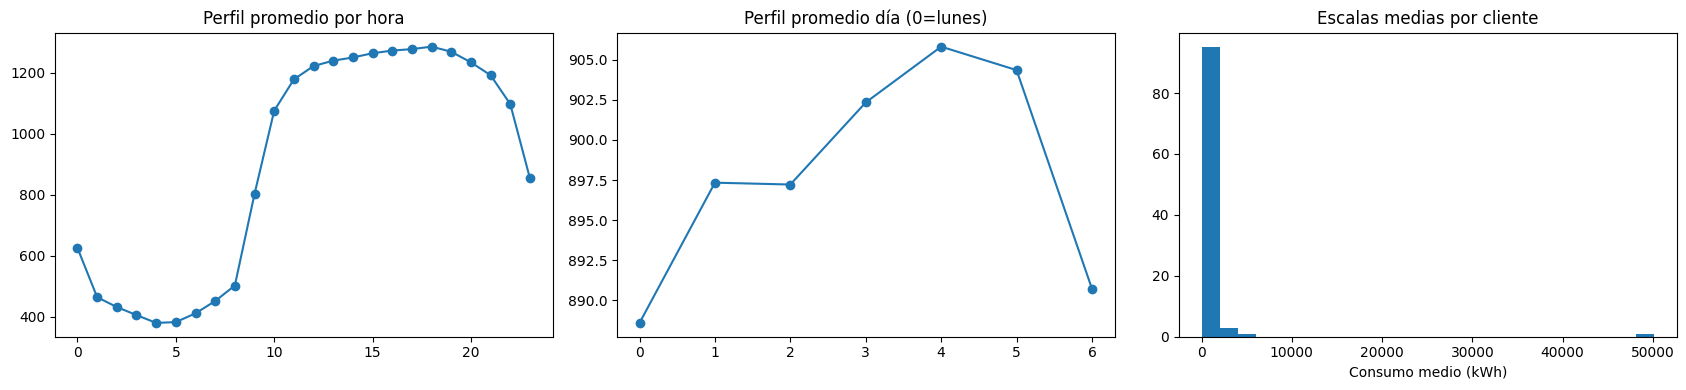

Escala media de consumo por cliente (kWh): {'min': 2.459451675415039, 'median': 159.49635314941406, 'max': 50132.25390625}
Promedio diario global de los feriados seleccionados:


,kWh_h_promedio
2012-01-01,552.931091
2012-12-25,546.639648
2013-01-01,523.471924
2013-12-25,492.037354
2014-01-01,507.366608
2014-12-25,439.501251


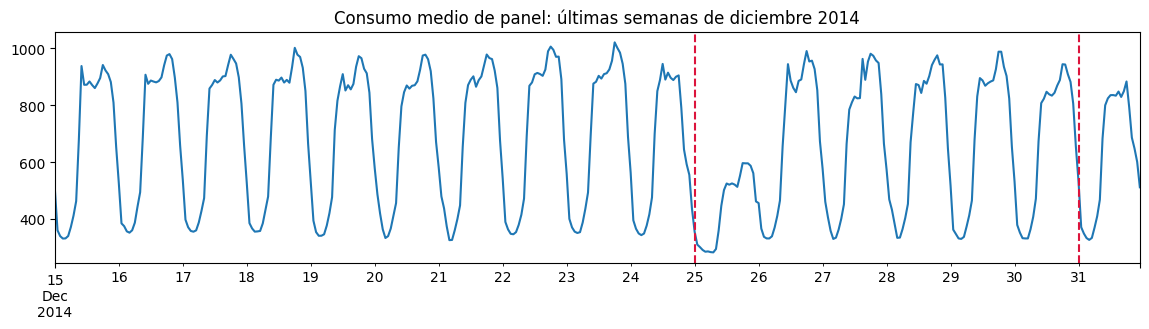

In [6]:
pt_holidays = holidays.country_holidays('PT', years=[2012, 2013, 2014])
calendar = pd.DataFrame(index=hourly.index)
calendar['hour'] = calendar.index.hour.astype(int)
calendar['weekday'] = calendar.index.dayofweek.astype(int)
calendar['month'] = calendar.index.month.astype(int)
calendar['holiday'] = np.fromiter((int(ts.date() in pt_holidays) for ts in calendar.index), dtype=np.int8)
for name, period, base in [('hour',24,0), ('weekday',7,0), ('month',12,1)]:
    angle = 2*np.pi*(calendar[name].to_numpy()-base)/period
    calendar[f'{name}_sin'] = np.sin(angle).astype('float32')
    calendar[f'{name}_cos'] = np.cos(angle).astype('float32')
CAL_COLS = ['hour_sin','hour_cos','weekday_sin','weekday_cos','month_sin','month_cos','holiday']
cal_np = calendar[CAL_COLS].to_numpy(dtype=np.float32)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
mean_agg = hourly.mean(axis=1)
mean_agg.groupby(mean_agg.index.hour).mean().plot(ax=axes[0], marker='o', title='Perfil promedio por hora')
mean_agg.groupby(mean_agg.index.dayofweek).mean().plot(ax=axes[1], marker='o', title='Perfil promedio día (0=lunes)')
axes[2].hist(hourly.mean(axis=0).to_numpy(), bins=25)
axes[2].set(title='Escalas medias por cliente', xlabel='Consumo medio (kWh)')
plt.tight_layout(); plt.show()
scales = hourly.mean(axis=0)
print('Escala media de consumo por cliente (kWh):', scales.agg(['min','median','max']).to_dict())
# Día de Navidad y Año Nuevo vs resto de diciembre/enero.
special = mean_agg.loc[mean_agg.index.normalize().isin([
    pd.Timestamp(f'{y}-{m:02d}-{d:02d}') for y in (2012,2013,2014) for m,d in [(1,1),(12,25)]
])]
print('Promedio diario global de los feriados seleccionados:')
display(special.resample('D').mean().dropna().to_frame('kWh_h_promedio'))
ax = mean_agg.loc['2014-12-15':'2014-12-31'].plot(figsize=(14,3), title='Consumo medio de panel: últimas semanas de diciembre 2014')
for day in ['2014-12-25', '2014-12-31']: ax.axvline(pd.Timestamp(day), ls='--', color='crimson')
plt.show()

## 3. Partición temporal, normalización y Dataset de ventanas
Estandarización **por serie** usando exclusivamente el bloque de entrenamiento, con media y desviación estándar por cliente. La misma transformación se reutiliza en validación y prueba; la inversión devuelve kWh. El denominador MASE usa la diferencia estacional de 168 h **calculada solo en entrenamiento**. El contexto de validación/prueba puede extenderse al bloque temporal precedente (ya observado); solo el **objetivo** de cada ventana debe caer íntegramente dentro de su bloque.

In [7]:
idx = hourly.index
T0 = idx.get_loc(pd.Timestamp('2012-01-01 00:00:00'))
T_TR = idx.get_loc(pd.Timestamp('2014-07-01 00:00:00'))
T_VA = idx.get_loc(pd.Timestamp('2014-10-01 00:00:00'))
T_END = len(idx)
Y = hourly.to_numpy(dtype=np.float32).T.copy()  # [n_clientes, n_horas]
MEAN = Y[:, T0:T_TR].mean(axis=1).astype(np.float32)
STD = Y[:, T0:T_TR].std(axis=1).astype(np.float32)
STD = np.maximum(STD, 1e-3)
Z = ((Y - MEAN[:,None])/STD[:,None]).astype(np.float32)
# Escala estacional: denominador distinto por serie; 168h de rezago.
MASE_DEN = np.mean(np.abs(Y[:,168:T_TR] - Y[:,:T_TR-168]), axis=1)
MASE_DEN = np.where(MASE_DEN > 1e-8, MASE_DEN, np.nan)
assert np.isfinite(Z).all()
assert T_END-T_VA == 92*24
splits = {'train':(T0,T_TR), 'val':(T_TR,T_VA), 'test':(T_VA,T_END)}
print('Bloques (horas):', {k:b-a for k,(a,b) in splits.items()})

class SlidingPanelDataset(Dataset):
    """X: (L, 1+n_cal), y: (H,), future_calendar: (H,n_cal).
    El orden es serie > origen; n_ventanas=series*n_orígenes.
    """
    def __init__(self, which='train', lookback=168, horizon=24, stride=1, series_ids=None):
        self.lookback, self.horizon, self.which = lookback, horizon, which
        a,b = splits[which]
        self.origins = np.arange(max(a,lookback), b-horizon+1, stride, dtype=np.int32)
        self.series_ids = np.arange(len(clientes)) if series_ids is None else np.asarray(series_ids)
    def __len__(self): return len(self.series_ids)*len(self.origins)
    def __getitem__(self, item):
        nw = len(self.origins)
        ci, origin = int(self.series_ids[item//nw]), int(self.origins[item%nw])
        past = Z[ci, origin-self.lookback:origin,None]
        x = np.concatenate([past, cal_np[origin-self.lookback:origin]], axis=1)
        f = cal_np[origin:origin+self.horizon]
        target = Z[ci,origin:origin+self.horizon]
        return {'x':torch.from_numpy(x), 'future_cov':torch.from_numpy(f.copy()),
                'y':torch.from_numpy(target.copy()), 'client_idx':torch.tensor(ci, dtype=torch.long),
                'origin':torch.tensor(origin, dtype=torch.long)}

for split in ('train','val','test'):
    ds = SlidingPanelDataset(split,L,H,1)
    print(f'{split}: {len(ds):,} ventanas | {len(ds.origins):,} orígenes horarios × {len(clientes)} clientes')
example = SlidingPanelDataset('train')[0]
assert example['x'].shape == (L,1+len(CAL_COLS)) and example['y'].shape == (H,)
assert example['future_cov'].shape == (H,len(CAL_COLS))
print('Shape de una muestra:', {k:tuple(v.shape) for k,v in example.items()})

Bloques (horas): {'train': 21888, 'val': 2208, 'test': 2208}
train: 2,169,700 ventanas | 21,697 orígenes horarios × 100 clientes
val: 218,500 ventanas | 2,185 orígenes horarios × 100 clientes
test: 218,500 ventanas | 2,185 orígenes horarios × 100 clientes
Shape de una muestra: {'x': (168, 8), 'future_cov': (24, 7), 'y': (24,), 'client_idx': (), 'origin': ()}


### Auditoría explícita de las cuatro fugas
- **Split aleatorio de ventanas:** prohibido; los índices del *target* están contenidos enteramente en train/val/test.
- **Escalador sobre toda la serie:** prohibido; `MEAN`, `STD` y `MASE_DEN` se ajustan únicamente antes de 2014-07-01.
- **Early stopping con test:** prohibido; selección sobre las fechas de julio-septiembre exclusivamente.
- **Covariables desalineadas:** los valores futuros son únicamente calendario ya conocido; se prueba la correspondencia origen ↔ timestamp y la no superposición de target/contexto.

In [8]:
# Pruebas automatizadas (si una falla, NO continuar).
for name,(a,b) in splits.items():
    ds = SlidingPanelDataset(name, L, H, 1)
    assert ds.origins.min() >= a
    assert ds.origins.max()+H <= b
    assert ds.origins.min() >= L
    assert np.all(np.diff(ds.origins) == 1)
assert not np.shares_memory(Y[:,:T_TR],Y[:,T_VA:])
assert np.allclose(MEAN, Y[:,:T_TR].mean(axis=1))
assert np.allclose(STD, np.maximum(Y[:,:T_TR].std(axis=1),1e-3))
for o in [T_TR,T_VA,T_VA+24,T_END-H]:
    assert idx[o-1]+pd.Timedelta(hours=1)==idx[o]
    assert np.allclose(cal_np[o:o+H], calendar.iloc[o:o+H][CAL_COLS].to_numpy())
    assert len(set(calendar.iloc[o:o+H].index)) == H
print('4 auditorías de fuga: APROBADAS; test bloqueado para tuneo.')

4 auditorías de fuga: APROBADAS; test bloqueado para tuneo.


## 4. Métricas y backtesting común
**Una sola interfaz** `backtest(modelo, bloque)` evalúa cualquier predictor que implemente `predict(origin, horizon)` y produzca matriz `(n_clientes,H)` en **kWh**. En test se consideran exactamente 92 orígenes a las 00:00. Los modelos pueden consultar las horas previas a cada origen, nunca los objetivos del origen actual. El MAPE sobre y≈0 es inestable: se reporta NaN cuando y=0 y la fracción de ceros.

**MASE**: MAE de predicción dividido por MAE del naïve estacional de 168 horas **sobre entrenamiento** de cada cliente. **WAPE**: suma absoluta de errores / suma absoluta real de todo el panel, no media de WAPE por cliente.

In [9]:
def point_metrics(y_true, y_pred, mase_den=MASE_DEN):
    # ambas matrices [origen, cliente, horizonte]
    e = np.asarray(y_pred,dtype=np.float64)-np.asarray(y_true,dtype=np.float64)
    a = np.abs(e); yt = np.asarray(y_true,dtype=np.float64)
    den = mase_den[None,:,None]
    mask = np.abs(yt) > 1e-8
    mape = float(np.mean(100*a[mask]/np.abs(yt[mask]))) if mask.any() else np.nan
    return {'MAE':float(a.mean()), 'RMSE':float(np.sqrt(np.mean(e**2))),
            'WAPE':float(100*a.sum()/np.maximum(np.abs(yt).sum(),1e-10)),
            'MAPE':mape, 'MASE':float(np.nanmean(a/den)),
            'fraccion_ceros':float((~mask).mean())}

class ForecastResult:
    def __init__(self, name, origins, truth, pred, seconds, q10=None, q90=None):
        self.name,self.origins,self.y,self.pred,self.seconds = name,origins,truth,pred,seconds
        self.q10,self.q90 = q10,q90
    def metrics(self):
        d = point_metrics(self.y,self.pred)
        if self.q10 is not None and self.q90 is not None:
            d['pinball_P10_P90'] = float((pinball(self.y,self.q10,.1)+pinball(self.y,self.q90,.9))/2)
            d['cobertura_P10_P90'] = float(np.mean((self.y>=self.q10)&(self.y<=self.q90)))
        return d

def pinball(y, qhat, tau):
    delta=np.asarray(y)-np.asarray(qhat)
    return np.mean(np.maximum(tau*delta,(tau-1)*delta))

def daily_origins(which):
    a,b=splits[which]
    return np.arange(a,b-H+1,24,dtype=np.int32)

RESULTS = {}
VALIDATION = {}
MODEL_META = {}

def backtest(modelo, which='test', name=None, save=True, horizon=H):
    a,b=splits[which]
    origins=np.arange(a,b-horizon+1,24,dtype=np.int32)
    truth=np.stack([Y[:,o:o+horizon] for o in origins],axis=0)
    preds, lows, highs=[],[],[]
    t0=time.perf_counter()
    for o in origins:
        out=modelo.predict(int(o), horizon=horizon)
        if isinstance(out,tuple):
            p,qlo,qhi=out
            lows.append(np.asarray(qlo,dtype=np.float32)); highs.append(np.asarray(qhi,dtype=np.float32))
        else: p=out
        p=np.asarray(p,dtype=np.float32)
        if p.shape!=(len(clientes),horizon):
            raise ValueError(f'Predicción {name or modelo}: forma {p.shape} ≠ {(len(clientes),horizon)}')
        if not np.isfinite(p).all(): raise ValueError('El modelo produjo NaN/Inf')
        preds.append(p)
    elapsed=time.perf_counter()-t0
    res=ForecastResult(name or type(modelo).__name__,origins,truth,np.stack(preds),elapsed,
                       np.stack(lows) if lows else None,np.stack(highs) if highs else None)
    if save:
        (RESULTS if which=='test' else VALIDATION)[res.name]=res
    return res

class NaiveAdapter:
    def __init__(self, period=None):
        self.period=period
    def predict(self, origin, horizon=24):
        if self.period is None: return np.repeat(Y[:,origin-1:origin],horizon,axis=1)
        offset = np.arange(horizon)%self.period
        return Y[:,origin-self.period+offset]

# Implementación vectorizada matemáticamente idéntica a StatsForecast Naive/SeasonalNaive
# y adaptada al mismo protocolo sin reentrenar pesos.
baselines={
    'Naive':NaiveAdapter(),
    'SeasonalNaive24':NaiveAdapter(24),
    'SeasonalNaive168':NaiveAdapter(168),
}
for name, adapter in baselines.items():
    r=backtest(adapter,'val',name)
    print('VALIDACIÓN',name, r.metrics())
for name, adapter in baselines.items():
    r=backtest(adapter,'test',name)
    MODEL_META[name]={'familia':'Baseline/StatsForecast-equivalente','L':168 if '168' in name else 24,
                      'estrategia':'Regla fija','covariables':False,'parametros':0,'entrenables':0,
                      'entrenamiento_s':0.,'hardware':'CPU'}
    print('PRUEBA',name, r.metrics())

VALIDACIÓN Naive {'MAE': 586.1682525878642, 'RMSE': 4931.379135804396, 'WAPE': 51.02353882822352, 'MAPE': 43.19908384388074, 'MASE': 3.772670997490473, 'fraccion_ceros': 0.007155797101449275}
VALIDACIÓN SeasonalNaive24 {'MAE': 78.31989988376858, 'RMSE': 773.9653221198072, 'WAPE': 6.81742560280171, 'MAPE': 19.428072185798108, 'MASE': 0.9473751846591394, 'fraccion_ceros': 0.007155797101449275}
VALIDACIÓN SeasonalNaive168 {'MAE': 117.1255505509248, 'RMSE': 1327.3363656366294, 'WAPE': 10.195298107545268, 'MAPE': 14.713264492168198, 'MASE': 1.018129133883875, 'fraccion_ceros': 0.007155797101449275}
PRUEBA Naive {'MAE': 337.74612851609356, 'RMSE': 2789.965591659982, 'WAPE': 42.84507084816503, 'MAPE': 40.24072099913738, 'MASE': 3.310405923113772, 'fraccion_ceros': 0.014067028985507246}
PRUEBA SeasonalNaive24 {'MAE': 69.41020449096634, 'RMSE': 626.6065501127785, 'WAPE': 8.80509020804178, 'MAPE': 18.413510019993172, 'MASE': 1.0099195015715972, 'fraccion_ceros': 0.014067028985507246}
PRUEBA Seas

## 5. Implementaciones propias: MLP, DLinear, NLinear, LSTM y encoder–decoder
Las arquitecturas originales comparten interfaz `(x, future_cov) → 24 valores normalizados`. Se usan dos LSTM multi-paso: pronóstico **directo** de 24 salidas y pronóstico **autorregresivo** de 1 paso realimentado. `Seq2Seq` recibe calendario conocido en su decoder; durante entrenamiento puede usar *teacher forcing*, pero **nunca** en validación o prueba.

En el trabajo escrito: `nn.LSTM(input_size,hidden_size,num_layers,batch_first,dropout)` devuelve `output:[B,L,D*hidden]`, `h_n:[D*capas,B,hidden]` y `c_n` con igual forma. `nn.GRU` devuelve `output` y `h_n`, **sin** `c_n`. En un modelo Conv1d dilatado causal con `k` fijo, el campo receptivo es `R=1+(k-1)*sum(dilations)` para una convolución por bloque; con dos convoluciones por bloque se duplican los incrementos. Un Transformer encoder usa `d_model`, `nhead` y `dim_feedforward`; se suman codificaciones posicionales al embedding para preservar orden temporal.

In [10]:
N_CAL = len(CAL_COLS)

class MultiOutputMLP(nn.Module):
    def __init__(self,L=168,H=24,hidden=128,dropout=.1):
        super().__init__(); self.L,self.H=L,H
        self.net=nn.Sequential(nn.Flatten(),nn.Linear(L*(1+N_CAL)+H*N_CAL,hidden),
           nn.ReLU(),nn.Dropout(dropout),nn.Linear(hidden,hidden),nn.ReLU(),nn.Linear(hidden,H))
    def forward(self,x,future_cov,y_teacher=None,teacher_forcing_ratio=0):
        return self.net(torch.cat([x.flatten(1),future_cov.flatten(1)],dim=1))

class DLinearOwn(nn.Module):
    def __init__(self,L=168,H=24,kernel=25):
        super().__init__(); self.L,self.H=L,H; self.kernel=kernel
        self.trend=nn.Linear(L,H); self.season=nn.Linear(L,H)
    def forward(self,x,future_cov,y_teacher=None,teacher_forcing_ratio=0):
        z=x[:,:,0]
        pad=(self.kernel-1)//2
        sm=nn.functional.avg_pool1d(nn.functional.pad(z[:,None,:],(pad,pad),mode='replicate'), self.kernel, stride=1).squeeze(1)
        return self.season(z-sm)+self.trend(sm)

class NLinearOwn(nn.Module):
    def __init__(self,L=168,H=24):
        super().__init__(); self.L,self.H=L,H; self.linear=nn.Linear(L,H)
    def forward(self,x,future_cov,y_teacher=None,teacher_forcing_ratio=0):
        z=x[:,:,0]; last=z[:,-1:]
        return self.linear(z-last)+last

class LSTMDirect(nn.Module):
    def __init__(self,L=168,H=24,hidden=64,layers=1,dropout=0.1):
        super().__init__(); self.L,self.H=L,H
        self.encoder=nn.LSTM(1+N_CAL,hidden,num_layers=layers,batch_first=True,
                             dropout=dropout if layers>1 else 0.0)
        self.head=nn.Sequential(nn.Dropout(dropout),nn.Linear(hidden+H*N_CAL,128),nn.ReLU(),nn.Linear(128,H))
    def forward(self,x,future_cov,y_teacher=None,teacher_forcing_ratio=0):
        _,(h,_)=self.encoder(x)
        return self.head(torch.cat([h[-1],future_cov.flatten(1)],dim=1))

class LSTMDecoder(nn.Module):
    def __init__(self,L=168,H=24,hidden=64,seq2seq=False):
        super().__init__(); self.L,self.H,self.seq2seq=L,H,seq2seq
        self.encoder=nn.LSTM(1+N_CAL,hidden,batch_first=True)
        self.decoder=nn.LSTMCell(1+(N_CAL if seq2seq else 0),hidden)
        self.head=nn.Linear(hidden,1)
    def forward(self,x,future_cov,y_teacher=None,teacher_forcing_ratio=0):
        _,(h,c)=self.encoder(x)
        h,c=h[-1],c[-1]
        prev=x[:,-1,0:1]; outputs=[]
        for t in range(self.H):
            dec_in=torch.cat([prev,future_cov[:,t,:]],dim=1) if self.seq2seq else prev
            h,c=self.decoder(dec_in,(h,c))
            p=self.head(h)
            outputs.append(p)
            if self.training and y_teacher is not None and teacher_forcing_ratio>0:
                selector=(torch.rand(p.shape[0],1,device=p.device)<teacher_forcing_ratio)
                prev=torch.where(selector,y_teacher[:,t:t+1],p)
            else: prev=p
        return torch.cat(outputs,dim=1)

FACTORIES = {
 'MLP':lambda l,h:MultiOutputMLP(l,h),
 'DLinear':lambda l,h:DLinearOwn(l,h),
 'NLinear':lambda l,h:NLinearOwn(l,h),
 'LSTM_Direct':lambda l,h:LSTMDirect(l,h),
 'LSTM_Autoregresiva':lambda l,h:LSTMDecoder(l,h,seq2seq=False),
 'Seq2Seq':lambda l,h:LSTMDecoder(l,h,seq2seq=True),
}
for name, factory in FACTORIES.items():
    net=factory(L,H).to(DEVICE)
    with torch.no_grad():
        zhat=net(torch.zeros(2,L,1+N_CAL,device=DEVICE),torch.zeros(2,H,N_CAL,device=DEVICE))
    assert zhat.shape==(2,H)
    print(f'{name:22s} parámetros = {sum(p.numel() for p in net.parameters()):,}')
    del net

MLP                    parámetros = 213,272
DLinear                parámetros = 8,112
NLinear                parámetros = 4,056
LSTM_Direct            parámetros = 51,864
LSTM_Autoregresiva     parámetros = 36,161
Seq2Seq                parámetros = 37,953


### Entrenamiento y early stopping
Se selecciona la mejor época **solo por MAE en validación**; se registra también MASE de validación, pérdida por época, tiempo, parámetros y memoria pico CUDA. El conjunto de ventanas tiene stride=1; para limitar tiempo en Colab se muestrean hasta `MAX_TRAIN_SAMPLES` por corrida, con semilla fija. El ajuste final reinicia los pesos y entrena sobre **train+val hasta 2014-09-30** durante el número de épocas seleccionado. No se accede a la prueba durante selección.

In [11]:
def make_dataset(lookback, until, start=0, horizon=H, validation=False, series_ids=None):
    ds=SlidingPanelDataset('val' if validation else 'train',lookback,horizon,1,series_ids)
    low=max(lookback, start if not validation else T_TR)
    high=until-horizon
    ds.origins=np.arange(low,high+1,1,dtype=np.int32)
    return ds

def sampled_loader(ds, n, batch_size=BATCH_SIZE, shuffle=True, seed=SEED):
    size=min(len(ds),int(n))
    ix=np.random.default_rng(seed).choice(len(ds),size=size,replace=False)
    subset=Subset(ds,ix.tolist())
    return DataLoader(subset,batch_size=batch_size,shuffle=shuffle,num_workers=0,pin_memory=(DEVICE.type=='cuda'))

def fit_own(net, train_ds, val_ds=None, epochs=EPOCHS, seed=SEED, lr=1e-3,
            train_samples=MAX_TRAIN_SAMPLES, val_samples=MAX_VALID_SAMPLES,
            early_stop=True, verbose=True):
    set_seed(seed)
    net=net.to(DEVICE)
    opt=torch.optim.Adam(net.parameters(),lr=lr)
    tr_loader=sampled_loader(train_ds,train_samples,shuffle=True,seed=seed)
    va_loader=sampled_loader(val_ds,val_samples,shuffle=False,seed=seed) if val_ds is not None else None
    best,wait,state,best_epoch=float('inf'),0,None,epochs
    logs=[]; begin=time.perf_counter()
    for epoch in range(1,epochs+1):
        if DEVICE.type=='cuda': torch.cuda.reset_peak_memory_stats()
        tick=time.perf_counter(); net.train(); loss_acc,n_acc=0,0
        for batch in tr_loader:
            xb,fb,yb=(batch[k].to(DEVICE,non_blocking=True) for k in ('x','future_cov','y'))
            opt.zero_grad(set_to_none=True)
            forcing=.40 if isinstance(net,LSTMDecoder) and net.seq2seq else 0.0
            pred=net(xb,fb,y_teacher=yb,teacher_forcing_ratio=forcing)
            loss=nn.functional.l1_loss(pred,yb)
            loss.backward(); nn.utils.clip_grad_norm_(net.parameters(),1.0); opt.step()
            n_acc+=len(xb); loss_acc+=float(loss.item())*len(xb)
        va_l,va_mae,va_mase=(np.nan,np.nan,np.nan)
        if va_loader is not None:
            net.eval(); total,nv,errs,mase_sum=0,0,0,0
            with torch.no_grad():
                for batch in va_loader:
                    xb,fb,yb=(batch[k].to(DEVICE,non_blocking=True) for k in ('x','future_cov','y'))
                    p=net(xb,fb); n=len(xb)
                    total+=float(torch.abs(p-yb).sum().item()); nv+=n*H
                    ci=batch['client_idx'].numpy(); e=np.abs((p-yb).cpu().numpy())*STD[ci,None]
                    errs+=float(e.sum()); mase_sum+=float(np.nansum(e/MASE_DEN[ci,None]))
            va_l=total/nv; va_mae=errs/nv; va_mase=mase_sum/nv
            if va_mae < best-1e-8:
                best,wait,state,best_epoch=va_mae,0,deepcopy(net.state_dict()),epoch
            else: wait+=1
        row={'epoch':epoch,'train_loss':loss_acc/max(n_acc,1),'val_loss':va_l,'val_MAE':va_mae,
             'val_MASE':va_mase,'epoch_s':time.perf_counter()-tick,
             'gpu_peak_MB':torch.cuda.max_memory_allocated()/1e6 if DEVICE.type=='cuda' else 0.}
        logs.append(row)
        if verbose: print(f"{type(net).__name__} ep={epoch:02d} tr={row['train_loss']:.4f} val_MAE={va_mae:.3f} val_MASE={va_mase:.3f} {row['epoch_s']:.1f}s")
        if va_loader is not None and early_stop and wait>=3: break
    if state is not None: net.load_state_dict(state)
    net.eval()
    return net,pd.DataFrame(logs),best_epoch,time.perf_counter()-begin

class OwnAdapter:
    def __init__(self,model,lookback=168): self.model,self.lookback=model.eval().to(DEVICE),lookback
    def predict(self,origin,horizon=24):
        assert horizon==self.model.H, 'Hay que entrenar un modelo con H requerido'
        zhist=Z[:,origin-self.lookback:origin]
        x=np.concatenate([zhist[:,:,None],np.broadcast_to(cal_np[origin-self.lookback:origin],
                         (len(clientes),self.lookback,N_CAL))],axis=2)
        fut=np.broadcast_to(cal_np[origin:origin+horizon],(len(clientes),horizon,N_CAL)).copy()
        with torch.no_grad():
            p=self.model(torch.as_tensor(x,device=DEVICE),torch.as_tensor(fut,device=DEVICE))
        return p.cpu().numpy()*STD[:,None]+MEAN[:,None]

OWN_VALID, OWN_TEST, OWN_LOGS = {}, {}, {}
for name, factory in FACTORIES.items():
    print('\n=== SELECCIÓN EN VALIDACIÓN:',name,'===')
    fitted, log, best_ep, secs=fit_own(factory(L,H),
           make_dataset(L,T_TR,start=T0),make_dataset(L,T_VA,validation=True))
    OWN_LOGS[name+'_seleccion']=log.assign(modelo=name,etapa='seleccion')
    OWN_VALID[name]=backtest(OwnAdapter(fitted,L),'val',name)
    print('Validación temporal MAE/MASE:',OWN_VALID[name].metrics()['MAE'],OWN_VALID[name].metrics()['MASE'])
    del fitted; gc.collect()
    # ajuste definitivo con train+val, sin uso de test y desde inicialización nueva
    fitted, log2, _, secs2=fit_own(factory(L,H),
           make_dataset(L,T_VA,start=T0),val_ds=None,epochs=max(1,best_ep),early_stop=False,verbose=False)
    OWN_LOGS[name+'_final']=log2.assign(modelo=name,etapa='final')
    OWN_TEST[name]=(fitted,L)
    n_total=sum(p.numel() for p in fitted.parameters())
    n_train=sum(p.numel() for p in fitted.parameters() if p.requires_grad)
    MODEL_META[name]={'familia':'Red propia/PyTorch','L':L,
        'estrategia':('Autoregresiva' if 'Autoregresiva' in name else 'Encoder-decoder' if name=='Seq2Seq' else 'Directa H=24'),
        'covariables':name in ['MLP','LSTM_Direct','Seq2Seq'],
        'parametros':n_total,'entrenables':n_train,'entrenamiento_s':secs2,'hardware':str(DEVICE),
        'mejor_epoch':best_ep}
    rr=backtest(OwnAdapter(fitted,L),'test',name)
    print('Prueba MAE/MASE:',rr.metrics()['MAE'],rr.metrics()['MASE'])
print('Terminado PyTorch propio. Modelos disponibles:',list(OWN_TEST))


=== SELECCIÓN EN VALIDACIÓN: MLP ===
MultiOutputMLP ep=01 tr=0.3868 val_MAE=114.493 val_MASE=1.072 2.5s
MultiOutputMLP ep=02 tr=0.2933 val_MAE=98.773 val_MASE=0.979 2.1s
MultiOutputMLP ep=03 tr=0.2793 val_MAE=99.016 val_MASE=0.958 2.1s
MultiOutputMLP ep=04 tr=0.2713 val_MAE=97.068 val_MASE=0.937 3.7s
MultiOutputMLP ep=05 tr=0.2674 val_MAE=93.551 val_MASE=0.924 2.3s
MultiOutputMLP ep=06 tr=0.2630 val_MAE=92.130 val_MASE=0.915 1.2s
MultiOutputMLP ep=07 tr=0.2590 val_MAE=93.656 val_MASE=0.905 1.2s
MultiOutputMLP ep=08 tr=0.2575 val_MAE=87.138 val_MASE=0.882 1.2s
MultiOutputMLP ep=09 tr=0.2555 val_MAE=90.200 val_MASE=0.899 1.2s
MultiOutputMLP ep=10 tr=0.2533 val_MAE=91.784 val_MASE=0.893 1.2s
Validación temporal MAE/MASE: 91.55498949969484 0.8797662034133948
Prueba MAE/MASE: 76.99090693293707 0.9031505766182804

=== SELECCIÓN EN VALIDACIÓN: DLinear ===
DLinearOwn ep=01 tr=0.3451 val_MAE=95.792 val_MASE=0.971 1.1s
DLinearOwn ep=02 tr=0.2584 val_MAE=84.889 val_MASE=0.883 1.1s
DLinearOwn ep=

### Comparación multi-paso: autorregresiva, directa y seq2seq
Todas las estrategias usan LSTM de capacidad comparable. La estrategia autorregresiva consume sus propias predicciones en inferencia, por lo que el error puede acumularse; la directa emite 24 valores de una sola vez; la seq2seq utiliza covariables de calendario en el decoder.

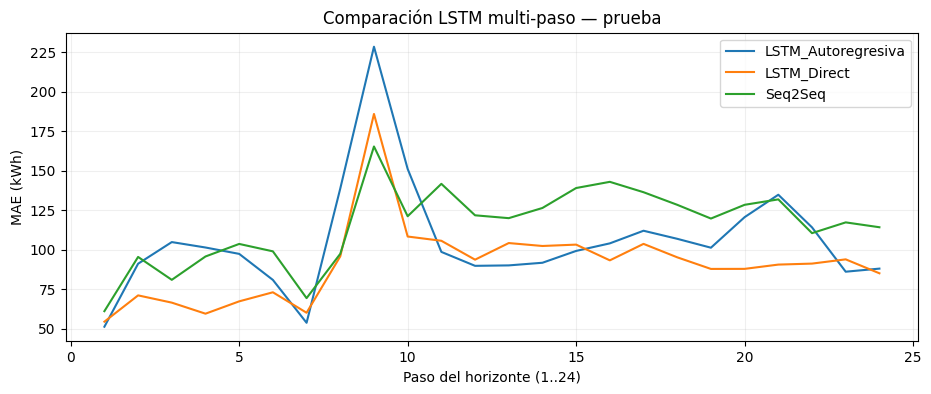

In [12]:
ar_names=['LSTM_Autoregresiva','LSTM_Direct','Seq2Seq']
plt.figure(figsize=(11,4))
for name in ar_names:
    r=RESULTS[name]
    plt.plot(np.arange(1,H+1),np.mean(np.abs(r.y-r.pred),axis=(0,1)),label=name)
plt.xlabel('Paso del horizonte (1..24)'); plt.ylabel('MAE (kWh)')
plt.title('Comparación LSTM multi-paso — prueba'); plt.legend();plt.grid(alpha=.2);plt.show()

## 6. LightGBM global, con rezagos y calendario
Un único regresor aprende en todos los clientes. Se entrena para **un paso** con rezagos 1–24 y 168 y atributos de calendario; para los 24 pasos del día se realimentan **sus predicciones** (no los valores reales del día futuro). Para ahorrar RAM se muestrean pares *(cliente, instante)* de los bloques permitidos. Se selecciona el número de árboles usando solo validación y posteriormente se reajusta una vez con train+val.

In [13]:
import lightgbm as lgb

def lgb_features(cids, tids, series=Y):
    cids=np.asarray(cids,dtype=np.int64); tids=np.asarray(tids,dtype=np.int64)
    lags=np.stack([series[cids,tids-lag] for lag in list(range(1,25))+[168]],axis=1)
    return np.concatenate([lags,cal_np[tids],cids[:,None].astype(np.float32)],axis=1).astype(np.float32)

def train_lgb(train_start,train_end,seed=SEED,n_samples=None,n_estimators=220,valid=True):
    rng=np.random.default_rng(seed)
    n_samples=n_samples or (90000 if QUICK_MODE else 400000)
    tmin=max(168,train_start)
    tt=rng.integers(tmin,train_end,size=n_samples)
    cc=rng.integers(0,len(clientes),size=n_samples)
    features=lgb_features(cc,tt); yy=Y[cc,tt]
    model=lgb.LGBMRegressor(n_estimators=n_estimators,learning_rate=.05,num_leaves=31,
            max_depth=-1,colsample_bytree=.9,random_state=seed,n_jobs=2,verbosity=-1)
    if valid:
        vcc=rng.integers(0,len(clientes),size=min(40000,n_samples//4))
        vtt=rng.integers(T_TR,T_VA,size=len(vcc))
        model.fit(features,yy,eval_set=[(lgb_features(vcc,vtt),Y[vcc,vtt])],
                  eval_metric='l1',callbacks=[lgb.early_stopping(stopping_rounds=25,verbose=False)])
    else: model.fit(features,yy)
    return model

class LightGBMAdapter:
    def __init__(self,model):self.model=model
    def predict(self,origin,horizon=24):
        # Cada nuevo lag 1..24 se rellena con el pronóstico si t >= origin.
        n=len(clientes); history=Y[:,origin-168:origin].copy()
        ids=np.arange(n,dtype=np.int64); predictions=[]
        for step in range(horizon):
            t=origin+step
            ff=np.concatenate([np.stack([history[:,-lag] for lag in list(range(1,25))+[168]],axis=1),
                               np.broadcast_to(cal_np[t],(n,N_CAL)),ids[:,None].astype('float32')],axis=1)
            p=np.asarray(self.model.predict(ff),dtype='float32')
            predictions.append(p)
            history=np.concatenate([history,p[:,None]],axis=1)
        return np.stack(predictions,axis=1)

t0=time.perf_counter()
LGB_VALID_MODEL=train_lgb(T0,T_TR,valid=True)
VALIDATION['LightGBM']=backtest(LightGBMAdapter(LGB_VALID_MODEL),'val','LightGBM')
best_trees=int(LGB_VALID_MODEL.best_iteration_ or LGB_VALID_MODEL.n_estimators)
print('LightGBM validation:',VALIDATION['LightGBM'].metrics(),'árboles óptimos:',best_trees)
LGB_FINAL_MODEL=train_lgb(T0,T_VA,valid=False,n_estimators=best_trees)
total=time.perf_counter()-t0
RESULTS['LightGBM']=backtest(LightGBMAdapter(LGB_FINAL_MODEL),'test','LightGBM')
MODEL_META['LightGBM']={'familia':'Árbol global','L':168,'estrategia':'Recursiva 1→24',
    'covariables':True,'parametros':np.nan,'entrenables':np.nan,
    'entrenamiento_s':total,'hardware':'CPU','nota_parametros':f'{best_trees} árboles; el conteo de pesos neuronales NO aplica'}
print('LightGBM prueba:',RESULTS['LightGBM'].metrics())

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

LightGBM validation: {'MAE': 151.8574881018574, 'RMSE': 1060.0063698308925, 'WAPE': 13.218570617418713, 'MAPE': 215.78652804326765, 'MASE': 11.38997484208637, 'fraccion_ceros': 0.007155797101449275} árboles óptimos: 61


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

LightGBM prueba: {'MAE': 136.69446005068178, 'RMSE': 933.9353153308462, 'WAPE': 17.340491365970035, 'MAPE': 193.64353943656323, 'MASE': 11.817485293585055, 'fraccion_ceros': 0.014067028985507246}


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

## 7. StatsForecast: AutoETS y comprobación de las reglas naive
`StatsForecast` recibe columnas `unique_id, ds, y`, con una serie por cliente. Se invoca `AutoETS` como alternativa estadística. Para respetar el entrenamiento congelado, ajustamos el modelo con los datos **previos al bloque** y predecimos las 92 jornadas sin volver a ajustar pesos durante el bloque. Las reglas `Naive` y `SeasonalNaive` se computaron de manera vectorizada en la sección 4 (son equivalentes exactamente a sus reglas matemáticas en StatsForecast); aquí también se crean los modelos de la biblioteca y se comprueba su salida con un ejemplo de entrenamiento.

**Interpretación:** el naive estacional es un baseline actualizado automáticamente con valores observados hasta cada origen. El AutoETS congelado pronostica tres meses de una vez: no se le permite reajustarse diariamente con los valores reales de prueba; esto sigue el protocolo del PDF, aunque lo penaliza a largo plazo.

In [14]:
from statsforecast import StatsForecast
from statsforecast.models import Naive, SeasonalNaive, AutoETS

# Tabla larga: n_clientes × 26,304 horas. Puede utilizar ~300 MB de RAM.
long_df=hourly.stack().rename('y').reset_index()
long_df.columns=['ds','unique_id','y']
long_df['y']=long_df['y'].astype('float32')
long_df=long_df.sort_values(['unique_id','ds']).reset_index(drop=True)
print('Nixtla panel:',long_df.shape, '| IDs:',long_df.unique_id.nunique())

# Prueba corta de API StatsForecast, sin tocar prueba para calibración.
check_ids=clientes[:2]
check_cutoff=pd.Timestamp('2014-06-30 23:00')
check_df=long_df.loc[long_df.unique_id.isin(check_ids) & (long_df.ds<=check_cutoff)]
small_sf=StatsForecast(models=[Naive(),SeasonalNaive(season_length=24,alias='SeasonalNaive24'),SeasonalNaive(season_length=168,alias='SeasonalNaive168')],
                       freq='h',n_jobs=1)
small_out=small_sf.forecast(df=check_df,h=H)
display(small_out.head())
# Cada regla usa exactamente su último y conocido al corte.
for uid in check_ids:
    forecast=small_out.loc[small_out.unique_id==uid]
    row=Y[clientes.index(uid)]
    assert np.allclose(forecast['Naive'], row[T_TR-1], atol=1e-4)
    assert np.allclose(forecast['SeasonalNaive24'], row[T_TR-24:T_TR], atol=1e-4)
    # Algunas versiones asignan alias repetido; verificar columna 168 si está presente.
print('Comprobación de reglas Naive / SeasonalNaive24: correcta')

Nixtla panel: (2630400, 3) | IDs: 100


,unique_id,ds,Naive,SeasonalNaive24,SeasonalNaive168
0,MT_002,2014-07-01 00:00:00,30.049786,25.960171,24.893314
1,MT_002,2014-07-01 01:00:00,30.049786,21.337126,21.870554
2,MT_002,2014-07-01 02:00:00,30.049786,20.625889,20.625889
3,MT_002,2014-07-01 03:00:00,30.049786,20.270271,20.270269
4,MT_002,2014-07-01 04:00:00,30.049786,21.159317,21.159317


Comprobación de reglas Naive / SeasonalNaive24: correcta


### AutoETS con entrenamiento congelado


In [15]:
class LongTableAdapter:
    def __init__(self,fcst,model_col):
        self.values=fcst.pivot(index='ds',columns='unique_id',values=model_col).reindex(columns=clientes)
    def predict(self,origin,horizon=24):
        ts=idx[origin:origin+horizon]
        p=self.values.reindex(ts).to_numpy(dtype=np.float32).T
        if np.isnan(p).any(): raise RuntimeError('Faltan timestamps del pronóstico precomputado')
        return p

def autoets_block(cutoff_exclusive,block,model=None):
    model=AutoETS(season_length=24,model='ZZZ') if model is None else model
    df=long_df.loc[long_df.ds<idx[cutoff_exclusive]]
    n_hours=splits[block][1]-splits[block][0]
    t0=time.perf_counter()
    forecast=StatsForecast(models=[model],freq='h',n_jobs=2).forecast(df=df,h=n_hours)
    assert forecast.ds.min()==idx[cutoff_exclusive]
    return LongTableAdapter(forecast,'AutoETS'),time.perf_counter()-t0

if RUN_AUTOETS:
    auto_v,t_val=autoets_block(T_TR,'val')
    VALIDATION['AutoETS']=backtest(auto_v,'val','AutoETS')
    auto_t,t_final=autoets_block(T_VA,'test')
    RESULTS['AutoETS']=backtest(auto_t,'test','AutoETS')
    MODEL_META['AutoETS']={'familia':'StatsForecast','L':None,'estrategia':'H horizonte congelado',
      'covariables':False,'parametros':np.nan,'entrenables':np.nan,'entrenamiento_s':t_final,'hardware':'CPU'}
    print('AutoETS (val/test):',VALIDATION['AutoETS'].metrics(),RESULTS['AutoETS'].metrics())
else: print('AutoETS desactivado: no se incluirá en tabla, activar antes de entrega.')

AutoETS (val/test): {'MAE': 222.6363891784906, 'RMSE': 2270.088208987415, 'WAPE': 19.379583247083865, 'MAPE': 25.427921028339494, 'MASE': 1.6767085928919516, 'fraccion_ceros': 0.007155797101449275} {'MAE': 215.78202944644892, 'RMSE': 1808.6102831179694, 'WAPE': 27.373211885546173, 'MAPE': 31.956898041952186, 'MASE': 1.8882364545342536, 'fraccion_ceros': 0.014067028985507246}


## 8. NeuralForecast: N-HiTS, TCN, PatchTST, TFT y DeepAR probabilístico
Se requieren cuatro familias adicionales: residual (**NHITS**), convolucional causal (**TCN**), atención (**PatchTST** y **TFT**) y probabilística (**DeepAR**). Cada una se entrena globalmente con el mismo panel y se evalúa por la función única `backtest` (mediante un adaptador de predicciones). Para mantener **una sola actualización de pesos** antes del período evaluado, se utiliza `cross_validation(n_windows=92,step_size=24,refit=False)` de Nixtla: en validación inicia ajuste con datos anteriores a julio; en prueba se crea instancia nueva y entrena con datos anteriores a octubre. El framework mueve orígenes para la predicción sin reajustar los pesos de cada origen.

**DeepAR** produce una distribución; reportamos la predicción central y P10/P90, pinball loss y cobertura. Todas las fechas de características externas son conocidas a futuro. `TFT` cumple la elección «TFT o iTransformer» del PDF. Los demás modelos preservan el mínimo de 100 clientes.

In [17]:
from neuralforecast import NeuralForecast
from neuralforecast.models import NHITS, TCN, PatchTST, TFT, DeepAR
from neuralforecast.losses.pytorch import DistributionLoss

# En NeuralForecast se usan 7 columnas calendario, disponibles en todo el horizonte.
nixtla_calendar = calendar[CAL_COLS].reset_index()
nixtla_calendar = nixtla_calendar.rename(columns={nixtla_calendar.columns[0]:'ds'})
nf_df = long_df.merge(nixtla_calendar,on='ds',how='left',validate='many_to_one')
assert nf_df[CAL_COLS].notna().all().all()

def make_nf(name,steps=NF_STEPS,lookback=L,seed=SEED):
    common=dict(h=H,input_size=lookback,max_steps=steps,learning_rate=1e-3,
                batch_size=32,windows_batch_size=256,scaler_type='standard',
                random_seed=seed,alias=name)
    if name=='NHITS': return NHITS(**common,futr_exog_list=CAL_COLS)
    if name=='TCN': return TCN(**common,futr_exog_list=CAL_COLS)
    if name=='PatchTST': return PatchTST(**common,futr_exog_list=CAL_COLS)
    if name=='TFT': return TFT(**common,futr_exog_list=CAL_COLS,hidden_size=64)
    if name=='DeepAR':
        return DeepAR(**common,futr_exog_list=CAL_COLS,
          loss=DistributionLoss(distribution='StudentT',level=[80]),
          lstm_hidden_size=64,trajectory_samples=100)
    raise KeyError(name)

def nf_crossvalidate(name,until,block,lookback=L,steps=NF_STEPS,seed=SEED):
    # Todas las observaciones y covariables se incluyen en el objeto de CV;
    # refit=False exige ajustar una sola vez en el primer cutoff del bloque.
    df = nf_df.loc[nf_df.ds <= idx[until - 1]].copy()
    n_days=(splits[block][1]-splits[block][0])//24
    model=make_nf(name,steps=steps,lookback=lookback,seed=seed)
    runner=NeuralForecast(models=[model],freq='h')
    start=time.perf_counter()
    cv=runner.cross_validation(df=df,n_windows=n_days,step_size=24,refit=False,val_size=0)
    elapsed=time.perf_counter()-start
    assert pd.Timestamp(cv['ds'].min())==idx[splits[block][0]], 'CV tomó un bloque temporal erróneo'
    assert cv[['unique_id','ds']].duplicated().sum()==0,'Horizontes de CV superpuestos'
    return runner,cv,elapsed

class NixtlaCVAdapter(LongTableAdapter):
    def __init__(self,cv,name):
        self.name=name
        if name=='DeepAR':
            cols=[c for c in cv.columns if str(c).startswith(name)]
            point=next((c for c in cols if c==name),None)
            if point is None: point=next((c for c in cols if 'median' in str(c).lower()),None)
            if point is None: raise KeyError(f'No se encontró salida central DeepAR entre {cols}')
            self.low=LongTableAdapter(cv,next(c for c in cols if '-lo-80' in str(c)))
            self.high=LongTableAdapter(cv,next(c for c in cols if '-hi-80' in str(c)))
        else: point=name
        super().__init__(cv,point)
    def predict(self,origin,horizon=24):
        y=super().predict(origin,horizon)
        if self.name=='DeepAR':return y,self.low.predict(origin,horizon),self.high.predict(origin,horizon)
        return y

NF_MODELS=['NHITS','TCN','PatchTST','TFT','DeepAR']
NF_FITTED={}
if RUN_NEURALFORECAST:
    for nf_name in NF_MODELS:
        print('\nNeuralForecast:',nf_name,'→ validación')
        nf_val,cv_val,vt=nf_crossvalidate(nf_name,T_VA,'val')
        VALIDATION[nf_name]=backtest(NixtlaCVAdapter(cv_val,nf_name),'val',nf_name)
        print('Validación:',VALIDATION[nf_name].metrics())
        del nf_val,cv_val; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
        print('NeuralForecast:',nf_name,'→ prueba sin refit entre orígenes')
        nf_final,cv_test,tt=nf_crossvalidate(nf_name,T_END,'test')
        RESULTS[nf_name]=backtest(NixtlaCVAdapter(cv_test,nf_name),'test',nf_name)
        fitted_model=nf_final.models[0]
        params=sum(p.numel() for p in fitted_model.parameters())
        trainable=sum(p.numel() for p in fitted_model.parameters() if p.requires_grad)
        NF_FITTED[nf_name]=nf_final
        MODEL_META[nf_name]={'familia':'NeuralForecast','L':L,'estrategia':'Directa/probabilística',
           'covariables':True,'parametros':params,'entrenables':trainable,
           'entrenamiento_s':tt,'hardware':str(DEVICE)}
        print('Prueba:',RESULTS[nf_name].metrics())
        del cv_test;gc.collect()
else: print('NeuralForecast desactivado; activar antes de entregar el laboratorio completo.')


NeuralForecast: NHITS → validación


INFO:lightning_fabric.utilities.seed:Seed set to 2026
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name                ┃ Type          ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ loss                │ MAE           │      0 │ train │     0 │
│ 1 │ hist_cat_embeddings │ ModuleList    │      0 │ train │     0 │
│ 2 │ futr_cat_embeddings │ ModuleList    │      0 │ train │     0 │
│ 3 │ stat_cat_embeddings │ ModuleList    │      0 │ train │     0 │
│ 4 │ padder_train        │ ConstantPad1d │      0 │ train │     0 │
│ 5 │ scaler              │ TemporalNorm  │      0 │ train │     0 │
│ 6 │ blocks              │ ModuleList    │  4.2 M │ train │     0 │
└───┴─────────────────────┴───────────────┴────────┴───────┴───────┘

Trainable params: 4.2 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 4.2 M                                                                                                
Total estimated model params size (MB): 16.775                                                                     
Modules in train mode: 37                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

...

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Output()

Prueba: {'MAE': 3765.634396462111, 'RMSE': 192199.98801002355, 'WAPE': 477.69273688956156, 'MAPE': 573.9659814024258, 'MASE': 31.65714340917002, 'fraccion_ceros': 0.014067028985507246}

NeuralForecast: PatchTST → validación


INFO:lightning_fabric.utilities.seed:Seed set to 2026


Exception: PatchTST does not support future exogenous variables.

## 9. Chronos-Bolt zero-shot (sin entrenamiento)
Se usa `BaseChronosPipeline.predict_quantiles(inputs, prediction_length, quantile_levels)` con un tensor `(n_series, contexto)` y cuantiles P10/P50/P90. Es el **único modelo sin entrenamiento** del laboratorio. Se fija el modelo `amazon/chronos-bolt-small` (variante ligera de la familia Chronos-Bolt); se debe registrar esta variante exacta en el PDF. La inferencia usa solo historia anterior al origen. Requiere internet para descargar los pesos del repositorio de Hugging Face.

In [18]:
from chronos import BaseChronosPipeline
class ChronosAdapter:
    def __init__(self,pipeline,context_size=512):self.pipeline,self.context_size=pipeline,context_size
    def predict(self,origin,horizon=24):
        ctx=torch.from_numpy(Y[:,max(0,origin-self.context_size):origin].copy())
        q,avg=self.pipeline.predict_quantiles(ctx,prediction_length=horizon,
                                               quantile_levels=[.1,.5,.9])
        if isinstance(q,list): q=torch.stack(q).squeeze(1)
        if isinstance(avg,list):avg=torch.stack(avg).squeeze(1)
        q=np.asarray(q.detach().cpu() if hasattr(q,'detach') else q,dtype=np.float32)
        avg=np.asarray(avg.detach().cpu() if hasattr(avg,'detach') else avg,dtype=np.float32)
        assert q.shape==(len(clientes),horizon,3),q.shape
        return avg,q[:,:,0],q[:,:,2]

CHRONOS_ADAPTER=None
if RUN_CHRONOS:
    from_pretrained_start=time.perf_counter()
    pipeline=BaseChronosPipeline.from_pretrained('amazon/chronos-bolt-small',
                                               device_map='cuda' if DEVICE.type=='cuda' else 'cpu')
    CHRONOS_ADAPTER=ChronosAdapter(pipeline,512)
    VALIDATION['Chronos-Bolt-small']=backtest(CHRONOS_ADAPTER,'val','Chronos-Bolt-small')
    RESULTS['Chronos-Bolt-small']=backtest(CHRONOS_ADAPTER,'test','Chronos-Bolt-small')
    MODEL_META['Chronos-Bolt-small']={'familia':'Fundacional zero-shot','L':512,
      'estrategia':'Cuantiles directos','covariables':False,
      'parametros':sum(p.numel() for p in pipeline.model.parameters()),
      'entrenables':0,'entrenamiento_s':0.,'hardware':str(DEVICE)}
    print('Chronos validación:', VALIDATION['Chronos-Bolt-small'].metrics())
    print('Chronos prueba:', RESULTS['Chronos-Bolt-small'].metrics())
else: print('Chronos desactivado; activar para entregable completo.')

config.json:   0%|          | 0.00/1.12k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  191MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

Chronos validación: {'MAE': 70.79495547186367, 'RMSE': 735.1316271734077, 'WAPE': 6.162410098830004, 'MAPE': 10.79688546054252, 'MASE': 0.6826958581002333, 'fraccion_ceros': 0.007155797101449275, 'pinball_P10_P90': 16.94175910949707, 'cobertura_P10_P90': 0.8107382246376812}
Chronos prueba: {'MAE': 57.1577375549173, 'RMSE': 566.2043140515576, 'WAPE': 7.250793149934105, 'MAPE': 10.569992694209912, 'MASE': 0.6833936584197143, 'fraccion_ceros': 0.014067028985507246, 'pinball_P10_P90': 13.926432609558105, 'cobertura_P10_P90': 0.8057201086956521}


## 10. Investigación: fundamentos y herramientas
**Local vs global:** un modelo local usa solo el historial de un cliente, lo que permite especialización pero requiere entrenar y mantener cientos de modelos. Un modelo global aprende patrones compartidos usando muchas series e identifica la escala mediante normalización. *Teacher forcing:* en entrenamiento, el decoder puede recibir el valor real del paso anterior; en pronóstico real debe realimentar su **propia** predicción. Esto genera *exposure bias* si el entrenamiento es demasiado dependiente del teacher forcing.

**RevIN:** normaliza cada ventana por su media y desviación, luego invierte la transformación sobre la salida. Facilita adaptar modelos ante cambios de nivel/distribución; en este notebook se usa principalmente z-score por cliente ajustado en entrenamiento, y DLinear/NLinear como alternativas estables. **Pinball loss:** penaliza asimétricamente las predicciones de un cuantil τ: `max(τ(y−q), (τ−1)(y−q))`. **MASE** reescala el error respecto a una referencia naïve *calculada en entrenamiento* por serie; **WAPE** divide la suma de errores absolutos por el total de demanda real del panel. Ambos evitan unidades, pero WAPE puede verse dominado por los clientes grandes y ser indefinido si todos consumen cero.

**Nixtla:** `StatsForecast` y `NeuralForecast` usan tablas largas (`unique_id,ds,y`) y aceptan `cross_validation(n_windows, step_size, refit)`: `n_windows` cantidad de orígenes, `step_size=24` para moverlos diariamente; `refit=False` para pesos fijos y `refit` entero para reentrenamiento periódico. **Chronos-Bolt:** `BaseChronosPipeline.predict_quantiles(inputs, prediction_length, quantile_levels)` recibe contextos y produce cuantiles pronosticados de cada serie. **TransformerEncoderLayer:** `d_model` ancho de token, `nhead` cabezas de atención y `dim_feedforward` tamaño interno de la MLP; los embeddings se suman a un vector de posición antes del encoder. La TCN apila convoluciones causales dilatadas; su campo receptivo aumenta por la suma de dilataciones según kernel y número de capas.

## 11. Iteraciones obligatorias: L ∈ {48, 168, 336} y meses ∈ {3, 12, 30}
Los experimentos de configuración se efectúan **exclusivamente en validación**. Cada experimento registra curva por época, parámetros entrenables y totales, duración, memoria pico, MAE/MASE. Se realizan al menos tres variaciones de ventana con DLinear, y tres de historia con DLinear; otras comparaciones por meses se calculan más abajo. Mantener fija la normalización inicial al comparar meses aísla el efecto de las observaciones entregadas al optimizador (aunque los estadísticos del escalador provienen del bloque train completo).

DLinear | L= 48 MASE val= 0.9223219698032034
DLinear | L= 168 MASE val= 0.8323853223560294
DLinear | L= 336 MASE val= 0.8011568731952617
DLinear | historia= 3 meses, MASE val= 0.8355505136602556
DLinear | historia= 12 meses, MASE val= 0.8212580268356401


,modelo,L,H,meses,seed,parametros,entrenables,epoch_seleccionada,tiempo_s,gpu_max_MB,inferencia_val_92_s,MASE_validacion,MAE_validacion,n_train_windows
2,DLinear,336,24,30,2026,16176,16176,8,12.193008,218.085888,0.079299,0.801157,91.874710,2152900
4,DLinear,168,24,12,2026,8112,8112,9,11.396624,215.174656,0.062949,0.821258,87.877267,873700
1,DLinear,168,24,30,2026,8112,8112,6,10.427432,215.174656,0.062571,0.832385,89.395428,2169700
3,DLinear,168,24,3,2026,8112,8112,5,9.049957,215.174656,0.060980,0.835551,86.505301,216100
0,DLinear,48,24,30,2026,2352,2352,10,10.875665,213.090816,0.053208,0.922322,84.915054,2181700


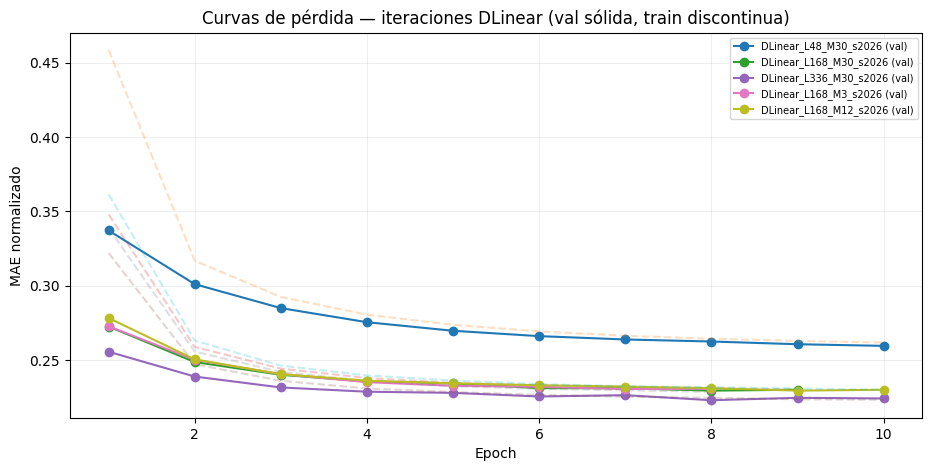

In [19]:
EXPERIMENT_ROWS=[]
EXPERIMENT_CURVES={}

def history_begin(months,cutoff=T_TR):
    begin=idx[cutoff]-pd.DateOffset(months=months)
    return max(0,int(idx.searchsorted(begin)))

def run_own_experiment(name,lookback,months=30,seed=SEED,epochs=None):
    start=history_begin(months)
    net=FACTORIES[name](lookback,H)
    net,log,best_ep,sec=fit_own(net,
        make_dataset(lookback,T_TR,start=start),make_dataset(lookback,T_VA,validation=True),
        epochs=epochs or EPOCHS,seed=seed,verbose=False)
    rr=backtest(OwnAdapter(net,lookback),'val',f'{name}_L{lookback}_M{months}_s{seed}',save=False)
    pars=sum(p.numel() for p in net.parameters())
    metrics=rr.metrics()
    key=f'{name}_L{lookback}_M{months}_s{seed}'
    EXPERIMENT_CURVES[key]=log
    row={'modelo':name,'L':lookback,'H':H,'meses':months,'seed':seed,
         'parametros':pars,'entrenables':sum(p.numel() for p in net.parameters() if p.requires_grad),
         'epoch_seleccionada':best_ep,'tiempo_s':sec,'gpu_max_MB':log.gpu_peak_MB.max(),
         'inferencia_val_92_s':rr.seconds, 'MASE_validacion':metrics['MASE'],
         'MAE_validacion':metrics['MAE'],'n_train_windows':len(make_dataset(lookback,T_TR,start=start))}
    EXPERIMENT_ROWS.append(row)
    return rr,net

if RUN_EXTENDED:
    for Lexp in (48,168,336):
        r,model=run_own_experiment('DLinear',Lexp,30)
        print('DLinear | L=',Lexp, 'MASE val=',r.metrics()['MASE'])
        del r,model;gc.collect()
    for months in (3,12,30):
        if months==30: continue  # ya está DLinear L168 M30
        r,model=run_own_experiment('DLinear',168,months)
        print('DLinear | historia=',months, 'meses, MASE val=',r.metrics()['MASE'])
        del r,model;gc.collect()
    exp_table=pd.DataFrame(EXPERIMENT_ROWS)
    display(exp_table.sort_values('MASE_validacion'))
    pd.DataFrame(EXPERIMENT_ROWS).to_csv(EXPORT_DIR/'iteraciones_hiperparametros.csv',index=False)
    # Más de tres curvas de pérdida, con parámetros/ejes correctos.
    plt.figure(figsize=(11,5))
    for key in list(EXPERIMENT_CURVES)[:5]:
        e=EXPERIMENT_CURVES[key]
        plt.plot(e.epoch,e.val_loss,marker='o',label=key+' (val)')
        plt.plot(e.epoch,e.train_loss,alpha=.25,ls='--')
    plt.title('Curvas de pérdida — iteraciones DLinear (val sólida, train discontinua)')
    plt.xlabel('Epoch');plt.ylabel('MAE normalizado');plt.legend(fontsize=7);plt.grid(alpha=.2);plt.show()
else: print('Activar RUN_EXTENDED para las iteraciones exigidas.')

### Gráficas y relación entre pérdida y generalización
Una pérdida de entrenamiento más baja **no garantiza** menor MASE de validación: sobreajuste, heterogeneidad entre clientes, transformaciones y el denominador del MASE modifican el orden. La siguiente celda mide la correlación real en lugar de afirmar el resultado antes de entrenar.

In [20]:
if EXPERIMENT_CURVES:
    for name,log in list(EXPERIMENT_CURVES.items())[:3]:
        print(name,'epoch de menor loss train:',int(log.loc[log.train_loss.idxmin(),'epoch']),
              '| epoch de mejor MASE val:',int(log.loc[log.val_MASE.idxmin(),'epoch']))

DLinear_L48_M30_s2026 epoch de menor loss train: 10 | epoch de mejor MASE val: 10
DLinear_L168_M30_s2026 epoch de menor loss train: 9 | epoch de mejor MASE val: 8
DLinear_L336_M30_s2026 epoch de menor loss train: 10 | epoch de mejor MASE val: 8


## 12. Modelo local vs global (10 clientes)
Elegimos el mejor modelo PyTorch según **validación** (no prueba), lo reentrenamos para cada uno de diez clientes únicamente con su serie, y calculamos MASE en esos diez clientes. El modelo global comparado es el mismo ya evaluado en test y fue entrenado sobre los 100 clientes.

In [21]:
own_best=min(OWN_VALID,key=lambda k:OWN_VALID[k].metrics()['MASE'])
print('Mejor modelo PROPIO elegido por validación:',own_best)
LOCAL_COMPARE=None
if RUN_EXTENDED:
    sub_ids=np.random.default_rng(SEED+1).choice(len(clientes),size=10,replace=False)
    global_pred=RESULTS[own_best].pred[:,sub_ids,:]
    actual=RESULTS[own_best].y[:,sub_ids,:]
    local_pred=np.zeros_like(global_pred)
    best_n_epochs=MODEL_META[own_best]['mejor_epoch']
    for j,ci in enumerate(sub_ids):
        model,_,_,_=fit_own(FACTORIES[own_best](L,H),
                make_dataset(L,T_VA,start=T0,series_ids=[ci]),val_ds=None,
                epochs=best_n_epochs,train_samples=MAX_TRAIN_SAMPLES,verbose=False)
        # Predicción para la serie individual, pero usando calendario del origen.
        model.eval()
        for day,origin in enumerate(daily_origins('test')):
            x=np.concatenate([Z[ci,origin-L:origin,None],cal_np[origin-L:origin]],axis=1)
            f=cal_np[origin:origin+H]
            with torch.no_grad():
                pred=model(torch.from_numpy(x[None]).to(DEVICE),torch.from_numpy(f[None]).to(DEVICE))
            local_pred[day,j]=pred.detach().cpu().numpy()[0]*STD[ci]+MEAN[ci]
        del model
    err_loc=np.mean(np.abs(actual-local_pred),axis=(0,2))/MASE_DEN[sub_ids]
    err_glo=np.mean(np.abs(actual-global_pred),axis=(0,2))/MASE_DEN[sub_ids]
    LOCAL_COMPARE=pd.DataFrame({'cliente':[clientes[x] for x in sub_ids],
                                'MASE_local':err_loc,'MASE_global':err_glo,
                                'mejora_global':err_loc-err_glo})
    display(LOCAL_COMPARE)
    LOCAL_COMPARE.to_csv(EXPORT_DIR/'local_vs_global.csv',index=False)

Mejor modelo PROPIO elegido por validación: NLinear


,cliente,MASE_local,MASE_global,mejora_global
0,MT_105,0.842789,0.889239,-0.046450
1,MT_197,0.849786,0.850942,-0.001156
2,MT_002,0.354405,0.375648,-0.021243
3,MT_345,1.002254,1.021659,-0.019404
4,MT_154,0.687667,0.832440,-0.144774
5,MT_218,0.645580,0.650877,-0.005297
6,MT_058,0.677567,0.679305,-0.001737
7,MT_040,0.338961,0.333646,0.005316
8,MT_189,0.669790,0.702838,-0.033048
9,MT_193,0.625197,0.652748,-0.027552


## 13. Reentrenamiento mensual con ventana expandible
Se seleccionan los ganadores **en validación**. Se reentrena el mejor deep-learning una sola vez al empezar **octubre, noviembre y diciembre** sobre toda la historia disponible hasta las 23:00 del día previo. Dentro de cada mes se mantienen los pesos y se evalúan todos los orígenes diarios; se repite con el mejor baseline. Esto permite contrastar error mensual con el entrenamiento congelado en septiembre.

In [22]:
val_dl_candidates={k:v for k,v in VALIDATION.items() if k in FACTORIES or k in NF_MODELS}
best_dl=min(val_dl_candidates,key=lambda k:val_dl_candidates[k].metrics()['MASE'])
baseline_candidates={k:v for k,v in VALIDATION.items() if k in baselines or k=='AutoETS'}
best_baseline=min(baseline_candidates,key=lambda k:baseline_candidates[k].metrics()['MASE'])
print('Seleccionado por VALIDACIÓN -> deep learning:',best_dl,'| baseline:',best_baseline)
months=[('2014-10-01','2014-11-01'),('2014-11-01','2014-12-01'),('2014-12-01','2015-01-01')]

def to_pos(day):
    d=pd.Timestamp(day)
    return int(idx.searchsorted(d))

class DictForecastAdapter:
    def __init__(self,lookup):self.lookup=lookup
    def predict(self,origin,horizon=H):return self.lookup[(int(origin),int(horizon))]

MONTHLY_RESULTS={}
if RUN_EXTENDED:
    monthly_lookup={}
    monthly_times={}
    for mstart,mend in months:
        begin,end=to_pos(mstart),to_pos(mend)
        origin_list=np.arange(begin,end-H+1,24)
        tick=time.perf_counter()
        if best_dl in FACTORIES:
            ep=MODEL_META[best_dl]['mejor_epoch']
            net,_,_,_=fit_own(FACTORIES[best_dl](L,H),make_dataset(L,begin,start=T0),
                              val_ds=None,epochs=ep,verbose=False)
            adapter=OwnAdapter(net,L)
            for o in origin_list:monthly_lookup[(int(o),H)]=adapter.predict(int(o),H)
            del adapter,net
        else:
            # Nixtla CV sobre el mes completo: ajuste al inicio de mes, sin refit diario.
            n_days=len(origin_list)
            df=nf_df.loc[nf_df.ds < pd.Timestamp(mend)]
            fresh=NeuralForecast(models=[make_nf(best_dl)],freq='h')
            cv=fresh.cross_validation(df=df,n_windows=n_days,step_size=24,refit=False,val_size=0)
            adapter=NixtlaCVAdapter(cv,best_dl)
            for o in origin_list:
                p=adapter.predict(int(o),H)
                monthly_lookup[(int(o),H)]=p[0] if isinstance(p,tuple) else p
            del fresh,cv,adapter
        monthly_times[mstart]=time.perf_counter()-tick
        print('Reentrenamiento DL:',mstart,'| días:',len(origin_list),'| seg:',round(monthly_times[mstart],1))
    monthly_dl=backtest(DictForecastAdapter(monthly_lookup),'test',f'{best_dl}_retrain_mensual',save=False)
    MONTHLY_RESULTS['DL']=monthly_dl

    base_lookup={}
    for mstart,mend in months:
        begin,end=to_pos(mstart),to_pos(mend)
        origin_list=np.arange(begin,end-H+1,24)
        if best_baseline in baselines:
            adapter=baselines[best_baseline]
        else:
            subdf=long_df.loc[long_df.ds < pd.Timestamp(mstart)]
            preds=StatsForecast(models=[AutoETS(season_length=24,model='ZZZ')],freq='h',n_jobs=2).forecast(
                    df=subdf,h=end-begin)
            adapter=LongTableAdapter(preds,'AutoETS')
        for o in origin_list:base_lookup[(int(o),H)]=adapter.predict(int(o),H)
    monthly_baseline=backtest(DictForecastAdapter(base_lookup),'test',f'{best_baseline}_retrain_mensual',save=False)
    MONTHLY_RESULTS['Baseline']=monthly_baseline
    print('MASE DL congelado/mensual:',RESULTS[best_dl].metrics()['MASE'],monthly_dl.metrics()['MASE'])
    print('MASE baseline congelado/mensual:',RESULTS[best_baseline].metrics()['MASE'],monthly_baseline.metrics()['MASE'])
    pd.DataFrame([{'modelo':v.name,**v.metrics()} for v in MONTHLY_RESULTS.values()]).to_csv(EXPORT_DIR/'reentrenamiento_mensual.csv',index=False)

Seleccionado por VALIDACIÓN -> deep learning: NLinear | baseline: SeasonalNaive24
Reentrenamiento DL: 2014-10-01 | días: 31 | seg: 9.7
Reentrenamiento DL: 2014-11-01 | días: 30 | seg: 9.5
Reentrenamiento DL: 2014-12-01 | días: 31 | seg: 9.5
MASE DL congelado/mensual: 0.8496819844272538 0.8493587567681414
MASE baseline congelado/mensual: 1.0099195015715972 1.0099195015715972


## 14. Experimento de historia de entrenamiento (3, 12 y 30 meses)
Se compara MASE de validación contra meses de historia para SeasonalNaive, LightGBM, DLinear, el mejor recurrente y PatchTST. Chronos se traza como referencia horizontal al ser zero-shot. Estos experimentos **no** cambian el tamaño de la muestra de clientes. Los resultados por meses son de **validación**, no se usan valores de prueba para ajustar hiperparámetros.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

┏━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name                ┃ Type              ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ loss                │ MAE               │      0 │ train │     0 │
│ 1 │ hist_cat_embeddings │ ModuleList        │      0 │ train │     0 │
│ 2 │ futr_cat_embeddings │ ModuleList        │      0 │ train │     0 │
│ 3 │ stat_cat_embeddings │ ModuleList        │      0 │ train │     0 │
│ 4 │ padder_train        │ ConstantPad1d     │      0 │ train │     0 │
│ 5 │ scaler              │ TemporalNorm      │      0 │ train │     0 │
│ 6 │ model               │ PatchTST_backbone │  466 K │ train │     0 │
└───┴─────────────────────┴───────────────────┴────────┴───────┴───────┘

Trainable params: 466 K                                                                                            
Non-trainable params: 3                                                                                            
Total params: 466 K                                                                                                
Total estimated model params size (MB): 1.867                                                                      
Modules in train mode: 93                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

...

Output()

/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_steps=83` reached.


INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Output()

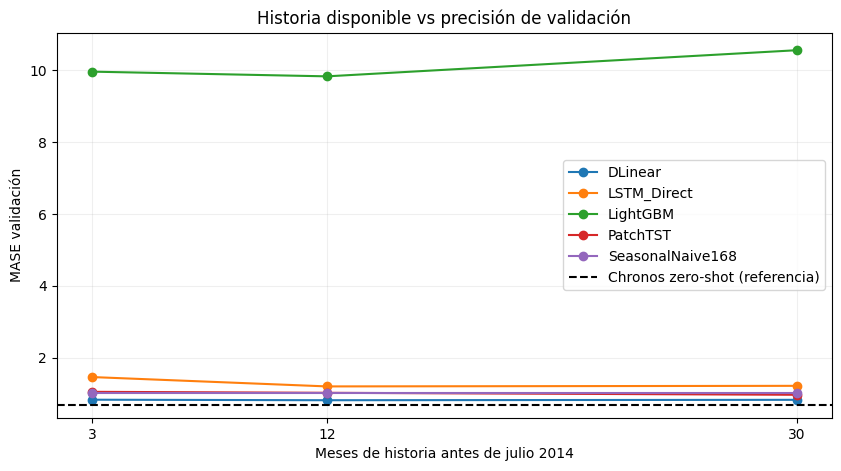

In [26]:
HISTORY_SCORES=[]
if RUN_EXTENDED:
    recurrent_names=['LSTM_Direct','LSTM_Autoregresiva','Seq2Seq']
    best_recurrent=min(recurrent_names,key=lambda k:VALIDATION[k].metrics()['MASE'])
    # Naive estacional usa únicamente la última semana, independiente de meses previos.
    for months in (3,12,30):
        HISTORY_SCORES.append({'modelo':'SeasonalNaive168','meses':months,
             'MASE':VALIDATION['SeasonalNaive168'].metrics()['MASE']})
        # LightGBM, ajustado exclusivamente en la historia indicada.
        lm=train_lgb(history_begin(months),T_TR,seed=SEED+months,n_samples=100000,
                     n_estimators=best_trees,valid=False)
        lm_r=backtest(LightGBMAdapter(lm),'val',save=False)
        HISTORY_SCORES.append({'modelo':'LightGBM','meses':months,'MASE':lm_r.metrics()['MASE']})
        del lm
        # Recuperar DLinear de los experimentos anteriores cuando exista.
        previous=[r for r in EXPERIMENT_ROWS if r['modelo']=='DLinear' and r['L']==L and r['meses']==months]
        if not previous:
            r,model=run_own_experiment('DLinear',L,months)
            del model
            score=r.metrics()['MASE']
        else:score=previous[0]['MASE_validacion']
        HISTORY_SCORES.append({'modelo':'DLinear','meses':months,'MASE':score})
        r,model=run_own_experiment(best_recurrent,L,months,epochs=max(2,EPOCHS//2))
        HISTORY_SCORES.append({'modelo':best_recurrent,'meses':months,'MASE':r.metrics()['MASE']})
        del model
        if RUN_NEURALFORECAST:
            # Para cada longitud histórica entrenar nuevo PatchTST usando solamente
            # los datos entre el inicio de historia y el corte previo a validación.
            # La validación empieza en julio, y no se hace refit dentro del bloque.
            hist_begin_ts=idx[history_begin(months)]
            df=nf_df.loc[(nf_df.ds>=hist_begin_ts)&(nf_df.ds<idx[T_VA])].copy()
            # cross_validation reserva julio-septiembre; no se usan para ajustar pesos.
            assert df.ds.max()==idx[T_VA-1], 'Faltan horas del bloque de validación'
            # Construcción explícita: segura aunque Colab conserve make_nf() antiguo.
            patchtst_model=PatchTST(
                h=H,input_size=L,max_steps=max(30,NF_STEPS//3),
                learning_rate=1e-3,batch_size=32,windows_batch_size=256,
                scaler_type='standard',random_seed=SEED,alias='PatchTST'
            )
            assert not patchtst_model.futr_exog_list, 'PatchTST no debe usar futr_exog_list'
            runner=NeuralForecast(models=[patchtst_model],freq='h')
            cv=runner.cross_validation(df=df,n_windows=92,step_size=24,refit=False,val_size=0)
            r=backtest(NixtlaCVAdapter(cv,'PatchTST'),'val',save=False)
            HISTORY_SCORES.append({'modelo':'PatchTST','meses':months,'MASE':r.metrics()['MASE']})
            del runner,cv
    history_table=pd.DataFrame(HISTORY_SCORES)
    history_table.to_csv(EXPORT_DIR/'mase_vs_meses.csv',index=False)
    fig,ax=plt.subplots(figsize=(10,5))
    for model,part in history_table.groupby('modelo'):
        ax.plot(part.meses,part.MASE,marker='o',label=model)
    if 'Chronos-Bolt-small' in VALIDATION:
        ax.axhline(VALIDATION['Chronos-Bolt-small'].metrics()['MASE'],ls='--',color='k',
                   label='Chronos zero-shot (referencia)')
    ax.set(xlabel='Meses de historia antes de julio 2014',ylabel='MASE validación',
           title='Historia disponible vs precisión de validación')
    ax.set_xticks([3,12,30]);ax.grid(alpha=.2);ax.legend();plt.show()
else:
    print('Ejecutar RUN_EXTENDED=True para la comparación de los 5 modelos contra meses.')

## 15. Sensibilidad a la semilla (3 entrenamientos)
Se repite el **mejor modelo deep-learning elegido por validación** con semillas diferentes. No se vuelven a seleccionar hiperparámetros sobre prueba: se mantiene la configuración inicial y se reentrena hasta 2014-09-30. El MASE se calcula con los mismos 92 orígenes, y se reporta la desviación estándar muestral (`ddof=1`).

In [27]:
SEED_RESULTS=[]
if RUN_EXTENDED:
    for seed in [2026, 2027, 2028]:
        if best_dl in FACTORIES:
            ep=MODEL_META[best_dl]['mejor_epoch']
            net,_,_,_=fit_own(FACTORIES[best_dl](L,H),make_dataset(L,T_VA,start=T0),
                               val_ds=None,epochs=ep,seed=seed,verbose=False)
            r=backtest(OwnAdapter(net,L),'test',save=False)
            del net
        else:
            runner,cv,_=nf_crossvalidate(best_dl,T_END,'test',seed=seed)
            r=backtest(NixtlaCVAdapter(cv,best_dl),'test',save=False)
            del runner,cv
        SEED_RESULTS.append({'modelo':best_dl,'seed':seed,'MASE':r.metrics()['MASE']})
        print('Seed',seed,'MASE=',r.metrics()['MASE'])
    display(pd.DataFrame(SEED_RESULTS))
    print('Media MASE =',np.mean([x['MASE'] for x in SEED_RESULTS]),
          '| desviación estándar muestral =',np.std([x['MASE'] for x in SEED_RESULTS],ddof=1))
    pd.DataFrame(SEED_RESULTS).to_csv(EXPORT_DIR/'sensibilidad_semillas.csv',index=False)

Seed 2026 MASE= 0.8505404778101779
Seed 2027 MASE= 0.8525755713919173
Seed 2028 MASE= 0.8519252445898154


,modelo,seed,MASE
0,NLinear,2026,0.850540
1,NLinear,2027,0.852576
2,NLinear,2028,0.851925


Media MASE = 0.8516804312639703 | desviación estándar muestral = 0.0010393996560480174


## 16. Métricas con horizonte H=168 (cuando aplica)
Para un horizonte de **168 horas** hay que definir un nuevo escenario de predicción (una semana por origen). Los Naive y SeasonalNaive se extienden sin reentrenar y permiten un MASE H168 legítimo con los mismos orígenes móviles mientras la semana objetivo quepa en prueba. Las redes entrenadas para H=24 **no deben evaluarse como H=168 simplemente repitiendo pronósticos**: es necesario volver a entrenar una versión H=168 y decidir nueva estrategia de covariables. Por eso quedan como `N/A` salvo que se extiendan correctamente.

In [28]:
H168_METRICS={}
if RUN_EXTENDED:
    for model_name,adapter in baselines.items():
        rr=backtest(adapter,'test',name=model_name+'_H168',save=False,horizon=168)
        H168_METRICS[model_name]=rr.metrics()['MASE']
    if CHRONOS_ADAPTER is not None:
        # Chronos zero-shot permite H168 directamente, sin modificar pesos.
        rr=backtest(CHRONOS_ADAPTER,'test',name='Chronos_H168',save=False,horizon=168)
        H168_METRICS['Chronos-Bolt-small']=rr.metrics()['MASE']
    print('MASE H=168 (misma definición train del denominador):',H168_METRICS)

/usr/local/lib/python3.13/dist-packages/chronos/chronos_bolt.py:550: UserWarning: We recommend keeping prediction length <= 64. The quality of longer predictions may degrade since the model is not optimized for it. 
  warnings.warn(msg)


MASE H=168 (misma definición train del denominador): {'Naive': 3.3882332548814684, 'SeasonalNaive24': 1.1797677205089092, 'SeasonalNaive168': 0.980844096344962, 'Chronos-Bolt-small': 0.8246678037189491}


## 17. Tabla comparativa, gráficas de prueba y diagnósticos
Se ordenan los modelos por **MASE de prueba**. Se añaden parámetros, costo y hardware; para modelos de Nixtla, el tiempo de `cross_validation` incluye fit+inferencia en una sola llamada y por rigor no se confunde el tiempo de acceso a la tabla precomputada con inferencia real. En esos casos el campo `tiempo_total_cv_s` registra el tiempo medido y el desglose se marca `N/D`. El número de árboles/hojas LightGBM **no** es directamente comparable con parámetros entrenables de una red neuronal.

,modelo,familia,L,H,estrategia,covariables,parametros_totales,parametros_entrenables,train_s,infer_92_s,...,hardware,MAE,RMSE,WAPE_pct,MAPE_pct,MASE,MASE_H168,MASE_semana_navidad,pinball_P10_P90,cobertura_P10_P90
0,Chronos-Bolt-small,Fundacional zero-shot,512.0,24,Cuantiles directos,False,47718016.0,0.0,0.0000,5.9574,...,cuda,57.1577,566.2043,7.2508,10.5700,0.6834,0.8247,1.3186,13.9264,0.8057
1,NLinear,Red propia/PyTorch,168.0,24,Directa H=24,False,4056.0,4056.0,9.0305,0.0544,...,cuda,68.6747,674.2430,8.7118,17.2582,0.8497,NaN,1.6754,NaN,NaN
2,DLinear,Red propia/PyTorch,168.0,24,Directa H=24,False,8112.0,8112.0,5.6245,0.0633,...,cuda,70.3623,680.7263,8.9259,17.5148,0.8574,NaN,1.6864,NaN,NaN
3,MLP,Red propia/PyTorch,168.0,24,Directa H=24,True,213272.0,213272.0,7.8913,0.0693,...,cuda,76.9909,691.3569,9.7667,16.5406,0.9032,NaN,1.5433,NaN,NaN
4,SeasonalNaive168,Baseline/StatsForecast-equivalente,168.0,24,Regla fija,False,0.0,0.0,0.0000,0.0024,...,CPU,91.8819,1073.4516,11.6558,15.3869,0.9755,0.9808,1.4972,NaN,NaN
5,SeasonalNaive24,Baseline/StatsForecast-equivalente,24.0,24,Regla fija,False,0.0,0.0,0.0000,0.0024,...,CPU,69.4102,626.6066,8.8051,18.4135,1.0099,1.1798,2.0226,NaN,NaN
6,LSTM_Direct,Red propia/PyTorch,168.0,24,Directa H=24,True,51864.0,51864.0,13.0699,0.1170,...,cuda,90.8743,757.0366,11.5279,21.0541,1.1111,NaN,1.7718,NaN,NaN
7,LSTM_Autoregresiva,Red propia/PyTorch,168.0,24,Autoregresiva,False,36161.0,36161.0,23.8694,0.3596,...,cuda,105.7022,899.9263,13.4089,23.1921,1.2371,NaN,1.9314,NaN,NaN
8,Seq2Seq,Red propia/PyTorch,168.0,24,Encoder-decoder,True,37953.0,37953.0,16.5057,0.4559,...,cuda,115.3342,964.0155,14.6308,21.9052,1.2724,NaN,1.9467,NaN,NaN
9,AutoETS,StatsForecast,NaN,24,H horizonte congelado,False,NaN,NaN,NaN,NaN,...,CPU,215.7820,1808.6103,27.3732,31.9569,1.8882,NaN,3.0216,NaN,NaN


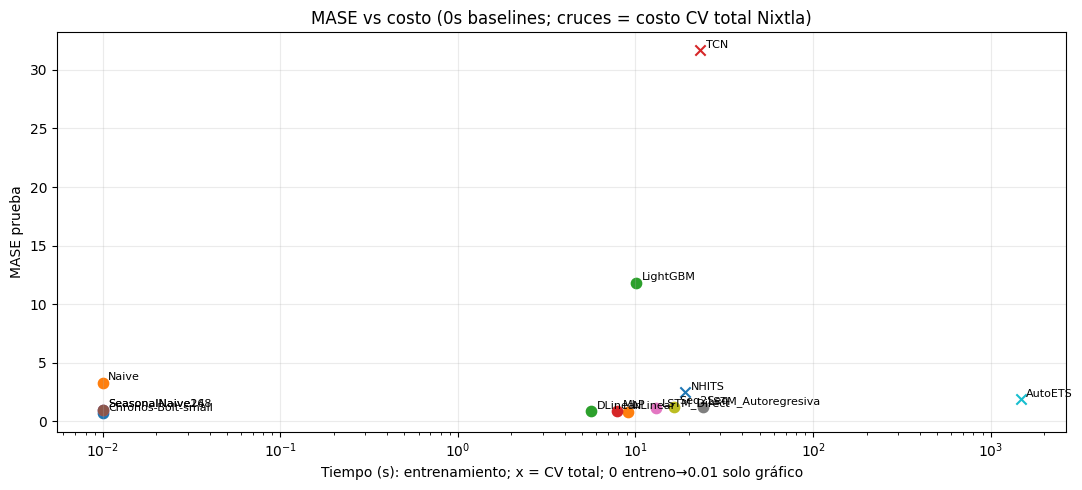

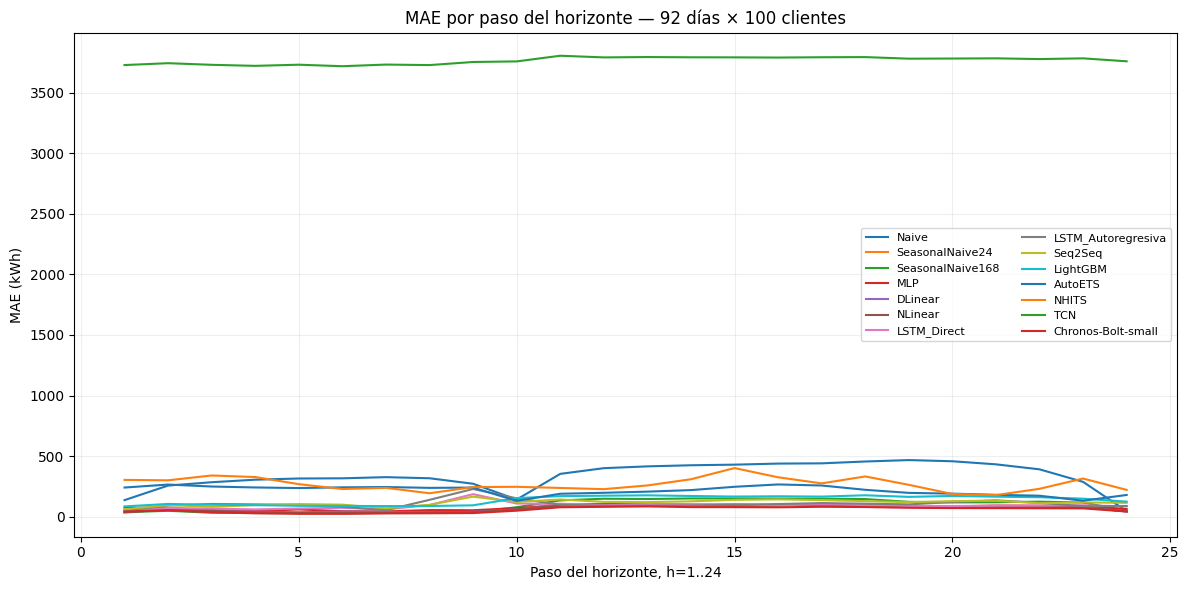

,Naive,SeasonalNaive24,SeasonalNaive168,MLP,DLinear,NLinear,LSTM_Direct,LSTM_Autoregresiva,Seq2Seq,LightGBM,AutoETS,NHITS,TCN,Chronos-Bolt-small
hora,,,,,,,,,,,,,,
0,136.445007,45.625999,35.942001,74.671997,39.910000,35.209999,54.555000,51.361000,61.188999,84.509003,240.324005,303.493011,3728.649902,42.004002
1,256.588013,68.735001,48.464001,70.098000,62.306999,59.824001,71.170998,91.177002,95.469002,105.083000,265.050995,300.032990,3744.052002,52.265999
2,284.201996,52.027000,32.353001,54.512001,47.744999,47.168999,66.584000,104.858002,80.994003,98.150002,248.774002,339.997009,3730.593994,36.761002
3,305.135986,39.167000,30.159000,45.834999,40.410000,37.265999,59.601002,101.430000,95.752998,94.897003,241.057999,326.966003,3722.029053,27.538000
4,315.011993,26.951000,28.679001,59.581001,36.051998,31.601999,67.397003,97.401001,103.683998,89.691002,236.065994,268.341003,3731.572021,23.819000
5,316.545990,27.827000,28.948000,45.306999,41.984001,31.738001,73.126999,80.944000,99.002998,88.752998,242.057007,228.113998,3719.034912,23.400999
6,326.114014,30.132999,30.893999,43.014000,40.007999,31.917999,60.194000,53.844002,69.419998,87.140999,244.522995,237.794998,3732.657959,26.782000
7,317.084991,34.792000,34.942001,54.462002,34.915001,35.074001,95.831001,138.701996,97.445999,87.901001,237.718994,193.274994,3728.395020,27.968000
8,271.622009,38.053001,37.023998,52.914001,39.500000,37.219002,185.830994,228.328003,165.276001,93.567001,239.998001,244.257996,3753.997070,29.649000


In [29]:
# Medición de CV por biblioteca tiene cronometraje combinado; marcarlo explícitamente.
rows=[]
for name,r in RESULTS.items():
    score=r.metrics()
    meta=MODEL_META.get(name,{})
    train_s=meta.get('entrenamiento_s',np.nan)
    inference_s=r.seconds
    cv_total=np.nan
    if name in NF_MODELS or name=='AutoETS':
        cv_total=train_s; train_s=np.nan; inference_s=np.nan
    rows.append({'modelo':name,'familia':meta.get('familia','N/D'),
                 'L':meta.get('L',np.nan),'H':H,'estrategia':meta.get('estrategia','N/D'),
                 'covariables':meta.get('covariables',False),
                 'parametros_totales':meta.get('parametros',np.nan),
                 'parametros_entrenables':meta.get('entrenables',np.nan),
                 'train_s':train_s,'infer_92_s':inference_s,
                 'tiempo_total_cv_s':cv_total,'hardware':meta.get('hardware','N/D'),
                 'MAE':score['MAE'],'RMSE':score['RMSE'],'WAPE_pct':score['WAPE'],
                 'MAPE_pct':score['MAPE'],'MASE':score['MASE'],
                 'MASE_H168':H168_METRICS.get(name,np.nan),
                 'MASE_semana_navidad':point_metrics(r.y[(idx[r.origins]>=pd.Timestamp('2014-12-22')) &
                         (idx[r.origins]<pd.Timestamp('2014-12-29'))],
                         r.pred[(idx[r.origins]>=pd.Timestamp('2014-12-22')) &
                         (idx[r.origins]<pd.Timestamp('2014-12-29'))])['MASE'],
                 'pinball_P10_P90':score.get('pinball_P10_P90',np.nan),
                 'cobertura_P10_P90':score.get('cobertura_P10_P90',np.nan)})
comparison=pd.DataFrame(rows).sort_values('MASE').reset_index(drop=True)
display(comparison.round(4))
comparison.to_csv(EXPORT_DIR/'tabla_comparativa.csv',index=False)

# Fig. 1: ubicar TODOS los modelos; cero costo a x=1e-2 solo para log y
# Nixtla como cota superior 'tiempo CV completo', claramente distinguida.
fig,ax=plt.subplots(figsize=(11,5))
for _,rr in comparison.iterrows():
    x=float(rr['train_s']) if pd.notna(rr['train_s']) else float(rr['tiempo_total_cv_s'])
    if x<=0: x=0.01  # 0 no es representable en eje log
    marker='x' if pd.notna(rr['tiempo_total_cv_s']) else 'o'
    ax.scatter(x,rr['MASE'],s=55,marker=marker)
    ax.annotate(rr['modelo'],(x,rr['MASE']),xytext=(4,2),textcoords='offset points',fontsize=8)
ax.set(xscale='log',xlabel='Tiempo (s): entrenamiento; x = CV total; 0 entreno→0.01 solo gráfico',
       ylabel='MASE prueba',title='MASE vs costo (0s baselines; cruces = costo CV total Nixtla)')
ax.grid(alpha=.25);plt.tight_layout();plt.savefig(EXPORT_DIR/'pareto_mase_tiempo.png',dpi=150);plt.show()

# Fig. 2: MAE h=1..24, una curva por modelo, sin comparar solo un cliente.
fig,ax=plt.subplots(figsize=(12,6))
for name,r in RESULTS.items():
    ax.plot(np.arange(1,H+1),np.abs(r.y-r.pred).mean(axis=(0,1)),label=name)
ax.set(xlabel='Paso del horizonte, h=1..24',ylabel='MAE (kWh)',title='MAE por paso del horizonte — 92 días × 100 clientes')
ax.grid(alpha=.2);ax.legend(fontsize=8,ncol=2)
plt.tight_layout();plt.savefig(EXPORT_DIR/'mae_por_paso.png',dpi=150);plt.show()

# Error por hora del día, promedio por cliente, y resumen especial Navidad.
hour_errors=pd.DataFrame({name:np.abs(r.y-r.pred).mean(axis=(0,1)) for name,r in RESULTS.items()},
                         index=np.arange(24)).rename_axis('hora')
display(hour_errors.round(3))
hour_errors.to_csv(EXPORT_DIR/'mae_por_hora.csv')

### Métricas por cliente y errores en días festivos
Se reportan MAE, RMSE y MASE por cliente además de las métricas agregadas. Las gráficas de consumo real vs predicho permiten analizar específicamente la semana 22–28 de diciembre y los festivos 25 de diciembre y 1 de enero (el 1 de enero de 2014 cae en entrenamiento y el 1 de enero de 2015 queda fuera de los datos; Año Nuevo debe examinarse en la EDA histórica, no en la prueba).

MAE                        RMSE                \
                        median            max       median           max   
modelo                                                                     
AutoETS              31.344999   15558.485352    42.548000  1.800389e+04   
Chronos-Bolt-small   11.423000    3482.441895    19.132000  5.622812e+03   
DLinear              13.867000    4312.545898    21.846001  6.762942e+03   
LSTM_Autoregresiva   20.687000    6764.765137    27.669001  8.950338e+03   
LSTM_Direct          18.926001    5580.913086    25.377001  7.519026e+03   
LightGBM             71.139000    5583.187988    77.138000  9.233138e+03   
MLP                  15.116000    4836.046875    21.981001  6.871544e+03   
NHITS                44.029999   18471.005859   147.669998  6.047902e+04   
NLinear              13.744000    4154.819824    21.733999  6.697804e+03   
Naive                56.321999   22661.398438    74.049004  2.777987e+04   
SeasonalNaive168     16.572001    5988.711914    26.229000  1.069034e+04   
SeasonalNaive24      16.200001    3763.597900    27.627001  6.195616e+03   
Seq2Seq              21.561001    7533.144043    29.377001  9.587381e+03   
TCN                 544.486023  266316.656250  3658.821045  1.916211e+06   

                      MASE              
                    median         max  
modelo                                  
AutoETS              1.657   10.253000  
Chronos-Bolt-small   0.681    1.338000  
DLinear              0.809    2.322000  
LSTM_Autoregresiva   1.115    3.471000  
LSTM_Direct          0.994    3.541000  
LightGBM             2.598  215.962997  
MLP                  0.862    2.358000  
NHITS                2.377    5.249000  
NLinear              0.808    2.258000  
Naive                3.272    6.584000  
SeasonalNaive168     0.955    2.372000  
SeasonalNaive24      0.903    3.638000  
Seq2Seq              1.140    3.430000  
TCN                 30.813   56.532001

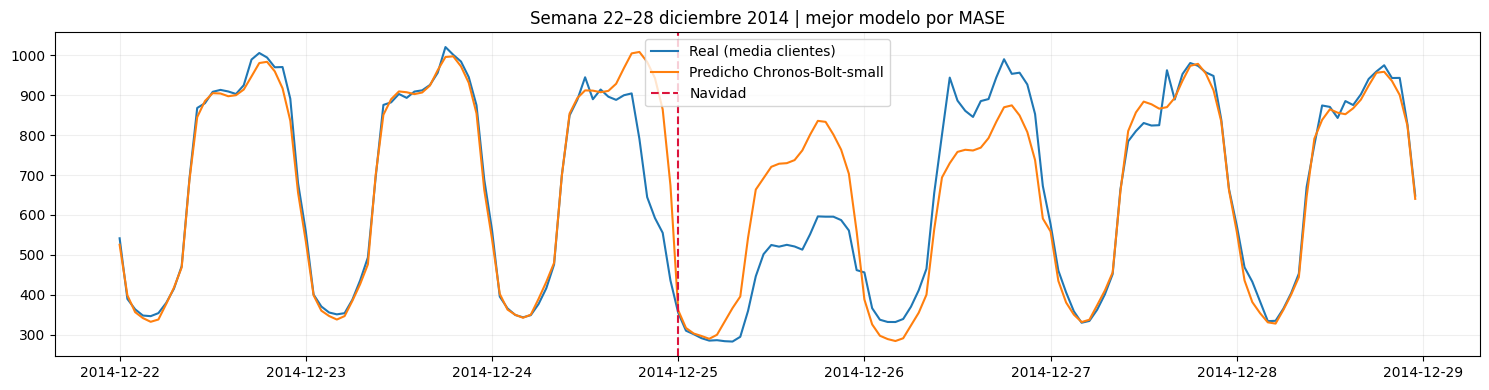

In [30]:
client_rows=[]
for name,r in RESULTS.items():
    ee=r.pred-r.y
    per_mae=np.abs(ee).mean(axis=(0,2))
    per_rmse=np.sqrt((ee**2).mean(axis=(0,2)))
    for c,uid in enumerate(clientes):
        client_rows.append({'modelo':name,'unique_id':uid,
            'MAE':per_mae[c],'RMSE':per_rmse[c],
            'MASE':per_mae[c]/MASE_DEN[c] if np.isfinite(MASE_DEN[c]) else np.nan})
client_metrics=pd.DataFrame(client_rows)
client_metrics.to_csv(EXPORT_DIR/'metricas_por_cliente.csv',index=False)
display(client_metrics.groupby('modelo')[['MAE','RMSE','MASE']].agg(['median','max']).round(3))

best_name=str(comparison.loc[0,'modelo'])
r=RESULTS[best_name]
mask=(idx[r.origins]>=pd.Timestamp('2014-12-22')) & (idx[r.origins]<pd.Timestamp('2014-12-29'))
actual_week=r.y[mask].mean(axis=1).reshape(-1)
pred_week=r.pred[mask].mean(axis=1).reshape(-1)
plt.figure(figsize=(15,4))
plt.plot(pd.date_range('2014-12-22',periods=168,freq='h'),actual_week,label='Real (media clientes)')
plt.plot(pd.date_range('2014-12-22',periods=168,freq='h'),pred_week,label=f'Predicho {best_name}')
plt.axvline(pd.Timestamp('2014-12-25'),color='crimson',ls='--',label='Navidad')
plt.title('Semana 22–28 diciembre 2014 | mejor modelo por MASE')
plt.legend();plt.grid(alpha=.2);plt.tight_layout();plt.savefig(EXPORT_DIR/'navidad.png',dpi=150);plt.show()

## 18. Exportar archivo de pronósticos y comprobar integridad
Se genera un CSV comprimido con columnas **`unique_id, ds, modelo, y_hat`** para **cada modelo sobre los 92 días**. El archivo se escribe por modelo, para no mantener millones de filas duplicadas en RAM, y también se exportan la tabla de comparación, métricas de clientes y gráficas. Los CSV y PNG se guardan bajo `resultados_lab8`. El comprimido `.csv.gz` es compatible con pandas y Git LFS/Google Drive; descomprimir si el docente exige CSV sin compresión.

In [31]:
import gzip
out_file=EXPORT_DIR/'pronosticos_prueba_todos_modelos.csv.gz'
first=True
with gzip.open(out_file,'wt',encoding='utf-8',newline='') as stream:
    for name,r in RESULTS.items():
        # r.pred=[92,100,24], para cada día: cliente > hora
        date_array=np.asarray(idx)[r.origins[:,None]+np.arange(H)]
        df=pd.DataFrame({
           'unique_id':np.tile(np.repeat(np.asarray(clientes),H),len(r.origins)),
           'ds':np.repeat(date_array, len(clientes),axis=0).reshape(-1),
           'modelo':name,
           'y_hat':r.pred.reshape(-1)})
        df.to_csv(stream,index=False,header=first,float_format='%.6f')
        first=False
        del df
print('Pronósticos exportados:',out_file)
print('Modelos:',len(RESULTS),'| filas esperadas:',92*len(clientes)*24*len(RESULTS))
print('Archivos resultantes:')
for path in sorted(EXPORT_DIR.glob('*')):print(f' - {path.name} ({path.stat().st_size/1e6:.1f} MB)')

Pronósticos exportados: /content/resultados_lab8/pronosticos_prueba_todos_modelos.csv.gz
Modelos: 14 | filas esperadas: 3091200
Archivos resultantes:
 - iteraciones_hiperparametros.csv (0.0 MB)
 - local_vs_global.csv (0.0 MB)
 - mae_por_hora.csv (0.0 MB)
 - mae_por_paso.png (0.1 MB)
 - mase_vs_meses.csv (0.0 MB)
 - metricas_por_cliente.csv (0.1 MB)
 - navidad.png (0.2 MB)
 - pareto_mase_tiempo.png (0.1 MB)
 - pronosticos_prueba_todos_modelos.csv.gz (25.2 MB)
 - reentrenamiento_mensual.csv (0.0 MB)
 - sensibilidad_semillas.csv (0.0 MB)
 - tabla_comparativa.csv (0.0 MB)


In [32]:
import shutil
archive=shutil.make_archive(str(ROOT/'CC3092_resultados_lab8'),'zip',root_dir=EXPORT_DIR)
print('ZIP final:',archive)
# En Google Colab, puedes descargarlo ejecutando manualmente:
# from google.colab import files
# files.download(archive)

ZIP final: /content/CC3092_resultados_lab8.zip


## 19. Preguntas de discusión


In [33]:
winner=comparison.iloc[0]
sn24=RESULTS['SeasonalNaive24'].metrics()['MASE']
sn168=RESULTS['SeasonalNaive168'].metrics()['MASE']
print(f"Ganador en prueba: {winner['modelo']} MASE={winner['MASE']:.4f}")
print(f"Mejora porcentual vs SeasonalNaive24: {(sn24-winner['MASE'])/sn24*100:.2f}%")
print(f"Mejora porcentual vs SeasonalNaive168: {(sn168-winner['MASE'])/sn168*100:.2f}%")
for n in ('DLinear','PatchTST'):
    if n in RESULTS:print(n,'MASE=',RESULTS[n].metrics()['MASE'])
for n in ('LSTM_Direct','LSTM_Autoregresiva','Seq2Seq'):
    print(n,'MASE=',RESULTS[n].metrics()['MASE'])
if 'Chronos-Bolt-small' in RESULTS:
    print('Chronos MASE=',RESULTS['Chronos-Bolt-small'].metrics()['MASE'])
if LOCAL_COMPARE is not None:
    print('Clientes (de 10) que mejoran con modelo global:',int((LOCAL_COMPARE.mejora_global>0).sum()))
if SEED_RESULTS:
    print('Desv. estándar de MASE (3 semillas)=',np.std([v['MASE'] for v in SEED_RESULTS],ddof=1))
print('ATENCIÓN: el test solo contiene octubre-diciembre; Año Nuevo se describe sobre EDA histórica.')

Ganador en prueba: Chronos-Bolt-small MASE=0.6834
Mejora porcentual vs SeasonalNaive24: 32.33%
Mejora porcentual vs SeasonalNaive168: 29.94%
DLinear MASE= 0.857384472007606
LSTM_Direct MASE= 1.1111210497026207
LSTM_Autoregresiva MASE= 1.237078972597102
Seq2Seq MASE= 1.2723936121554098
Chronos MASE= 0.6833936584197143
Clientes (de 10) que mejoran con modelo global: 1
Desv. estándar de MASE (3 semillas)= 0.0010393996560480174
ATENCIÓN: el test solo contiene octubre-diciembre; Año Nuevo se describe sobre EDA histórica.
